In [1]:
#Import the libraries and dataframe
import pandas as pd
import numpy as np
df=pd.read_csv('BikeData.csv')
df

,Date,Rented_Bike Count,Hour,Temperature,Humidity(%),Wind_speed(m/s),Visibility (10m),Dew_point_temperature,Solar Radiation(MJ/m2),Rainfall(mm),Snowfall(cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2 C,37,2.2,2000,-17.6 C,NaN,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5 C,38,0.8,2000,-17.6 C,NaN,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6 C,39,1.0,2000,-17.7 C,NaN,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2 C,40,0.9,2000,-17.6 C,NaN,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6 C,36,2.3,2000,-18.6 C,NaN,0.0,0.0,Winter,No Holiday,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,30/11/2018,1003,19,4.2 C,34,2.6,1894,NaN,NaN,0.0,0.0,Autumn,No Holiday,Yes
8756,30/11/2018,764,20,3.4 C,37,2.3,2000,NaN,NaN,0.0,0.0,Autumn,No Holiday,Yes
8757,30/11/2018,694,21,2.6 C,39,0.3,1968,NaN,NaN,0.0,0.0,Autumn,No Holiday,Yes
8758,30/11/2018,712,22,2.1 C,41,1.0,1859,NaN,NaN,0.0,0.0,Autumn,No Holiday,Yes


In [5]:
# Check how many columns left
len(df.columns)

14

1. Data Cleaning

In [4]:
# Step 1 : Checking if there are any columns with only 1 unique value
df.nunique()

Date                       365
Rented_Bike Count         2166
Hour                        24
Temperature                546
Humidity(%)                 90
Wind_speed(m/s)             65
Visibility (10m)          1789
Dew_point_temperature      350
Solar Radiation(MJ/m2)     344
Rainfall(mm)                61
Snowfall(cm)                51
Seasons                      4
Holiday                      2
Functioning Day              2
dtype: int64

In [9]:
# Checking if there's 1 unique value column once again and dropping it
df_drop = df.nunique()[df.nunique() == 1].index
df_drop

Index([], dtype='object')

In [10]:
# check it out
df_dropped_cols = df.copy() # saving the original copy, in case we need it again later
df_dropped_cols = df_dropped_cols.drop(columns=df_drop)
df_dropped_cols

,Date,Rented_Bike Count,Hour,Temperature,Humidity(%),Wind_speed(m/s),Visibility (10m),Dew_point_temperature,Solar Radiation(MJ/m2),Rainfall(mm),Snowfall(cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2 C,37,2.2,2000,-17.6 C,NaN,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5 C,38,0.8,2000,-17.6 C,NaN,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6 C,39,1.0,2000,-17.7 C,NaN,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2 C,40,0.9,2000,-17.6 C,NaN,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6 C,36,2.3,2000,-18.6 C,NaN,0.0,0.0,Winter,No Holiday,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,30/11/2018,1003,19,4.2 C,34,2.6,1894,NaN,NaN,0.0,0.0,Autumn,No Holiday,Yes
8756,30/11/2018,764,20,3.4 C,37,2.3,2000,NaN,NaN,0.0,0.0,Autumn,No Holiday,Yes
8757,30/11/2018,694,21,2.6 C,39,0.3,1968,NaN,NaN,0.0,0.0,Autumn,No Holiday,Yes
8758,30/11/2018,712,22,2.1 C,41,1.0,1859,NaN,NaN,0.0,0.0,Autumn,No Holiday,Yes


In [11]:
#Check the columns again
len(df_dropped_cols.columns)

14

In [12]:
# Step 2 : Removing any columns that have just NULL values, meaning the unique value is 0
df_dropped_cols = df_dropped_cols.dropna(axis=1, how='all')
df_dropped_cols

,Date,Rented_Bike Count,Hour,Temperature,Humidity(%),Wind_speed(m/s),Visibility (10m),Dew_point_temperature,Solar Radiation(MJ/m2),Rainfall(mm),Snowfall(cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2 C,37,2.2,2000,-17.6 C,NaN,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5 C,38,0.8,2000,-17.6 C,NaN,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6 C,39,1.0,2000,-17.7 C,NaN,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2 C,40,0.9,2000,-17.6 C,NaN,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6 C,36,2.3,2000,-18.6 C,NaN,0.0,0.0,Winter,No Holiday,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,30/11/2018,1003,19,4.2 C,34,2.6,1894,NaN,NaN,0.0,0.0,Autumn,No Holiday,Yes
8756,30/11/2018,764,20,3.4 C,37,2.3,2000,NaN,NaN,0.0,0.0,Autumn,No Holiday,Yes
8757,30/11/2018,694,21,2.6 C,39,0.3,1968,NaN,NaN,0.0,0.0,Autumn,No Holiday,Yes
8758,30/11/2018,712,22,2.1 C,41,1.0,1859,NaN,NaN,0.0,0.0,Autumn,No Holiday,Yes


In [13]:
# Checking again how many columns left
len(df_dropped_cols.columns)

14

In [14]:
# Step 3 : Checking data types of each column if there's anything weird
df_dropped_cols.dtypes

Date                       object
Rented_Bike Count           int64
Hour                        int64
Temperature                object
Humidity(%)                 int64
Wind_speed(m/s)           float64
Visibility (10m)            int64
Dew_point_temperature      object
Solar Radiation(MJ/m2)    float64
Rainfall(mm)              float64
Snowfall(cm)              float64
Seasons                    object
Holiday                    object
Functioning Day            object
dtype: object

In [15]:
# Checking if there are some column names with an empty space or anthing 
print(df_dropped_cols.columns.tolist())

['Date', 'Rented_Bike Count', 'Hour', 'Temperature', 'Humidity(%)', 'Wind_speed(m/s)', 'Visibility (10m)', 'Dew_point_temperature', 'Solar Radiation(MJ/m2)', 'Rainfall(mm)', 'Snowfall(cm)', 'Seasons', 'Holiday', 'Functioning Day']


In [17]:
# Removing spaces inside the column names
df_dropped_cols.columns = (
    df_dropped_cols.columns
    .str.strip()
    .str.replace(' ', '_')
)

In [20]:
# Checking the names again
print(df_dropped_cols.columns.tolist())

['Date', 'Rented_Bike_Count', 'Hour', 'Temperature', 'Humidity(%)', 'Wind_speed(m/s)', 'Visibility_(10m)', 'Dew_point_temperature', 'Solar_Radiation(MJ/m2)', 'Rainfall(mm)', 'Snowfall(cm)', 'Seasons', 'Holiday', 'Functioning_Day']


In [22]:
# The 'Temperatrue' column is not right. It should be numerical
df_dropped_cols['Temperature']

0       -5.2 C
1       -5.5 C
2         -6 C
3       -6.2 C
4         -6 C
         ...  
8755     4.2 C
8756     3.4 C
8757     2.6 C
8758     2.1 C
8759     1.9 C
Name: Temperature, Length: 8760, dtype: object

In [23]:
# Moderfying the unit notation from object to a float by stripping

# Create a copy of the DataFrame
df_change = df_dropped_cols.copy()

# Clean the 'Temperature' column
df_change["Temperature"] = df_change["Temperature"].apply(lambda x: float(x.replace('C', '').replace(',', '')) if isinstance(x, str) else x)

# Display the updated 'Temperature' column
df_change["Temperature"]


0      -5.2
1      -5.5
2      -6.0
3      -6.2
4      -6.0
       ... 
8755    4.2
8756    3.4
8757    2.6
8758    2.1
8759    1.9
Name: Temperature, Length: 8760, dtype: float64

In [24]:
# Noticing the 'Dew_point_temperature' column is not right in the same sense
df_dropped_cols['Dew_point_temperature']

0       -17.6 C
1       -17.6 C
2       -17.7 C
3       -17.6 C
4       -18.6 C
         ...   
8755        NaN
8756        NaN
8757        NaN
8758        NaN
8759        NaN
Name: Dew_point_temperature, Length: 8760, dtype: object

In [25]:
# Clean the 'Dew_point_temperature' column
df_change["Dew_point_temperature"] = df_change["Dew_point_temperature"].apply(lambda x: float(x.replace('C', '').replace(',', '')) if isinstance(x, str) else x)

# Display the updated 'price' column
df_change["Dew_point_temperature"]

0      -17.6
1      -17.6
2      -17.7
3      -17.6
4      -18.6
        ... 
8755     NaN
8756     NaN
8757     NaN
8758     NaN
8759     NaN
Name: Dew_point_temperature, Length: 8760, dtype: float64

In [27]:
# Check again if there's anything weird with the datatype
df_change.dtypes

Date                       object
Rented_Bike_Count           int64
Hour                        int64
Temperature               float64
Humidity(%)                 int64
Wind_speed(m/s)           float64
Visibility_(10m)            int64
Dew_point_temperature     float64
Solar_Radiation(MJ/m2)    float64
Rainfall(mm)              float64
Snowfall(cm)              float64
Seasons                    object
Holiday                    object
Functioning_Day            object
dtype: object

In [28]:
# Noticing 'Date' is not right
df_change

,Date,Rented_Bike_Count,Hour,Temperature,Humidity(%),Wind_speed(m/s),Visibility_(10m),Dew_point_temperature,Solar_Radiation(MJ/m2),Rainfall(mm),Snowfall(cm),Seasons,Holiday,Functioning_Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,NaN,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,NaN,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,NaN,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,NaN,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,NaN,0.0,0.0,Winter,No Holiday,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,30/11/2018,1003,19,4.2,34,2.6,1894,NaN,NaN,0.0,0.0,Autumn,No Holiday,Yes
8756,30/11/2018,764,20,3.4,37,2.3,2000,NaN,NaN,0.0,0.0,Autumn,No Holiday,Yes
8757,30/11/2018,694,21,2.6,39,0.3,1968,NaN,NaN,0.0,0.0,Autumn,No Holiday,Yes
8758,30/11/2018,712,22,2.1,41,1.0,1859,NaN,NaN,0.0,0.0,Autumn,No Holiday,Yes


In [29]:
# Changing the format of the date
df_change["Date"] = pd.to_datetime(df_change["Date"], format="%d/%m/%Y")
df_change

,Date,Rented_Bike_Count,Hour,Temperature,Humidity(%),Wind_speed(m/s),Visibility_(10m),Dew_point_temperature,Solar_Radiation(MJ/m2),Rainfall(mm),Snowfall(cm),Seasons,Holiday,Functioning_Day
0,2017-12-01,254,0,-5.2,37,2.2,2000,-17.6,NaN,0.0,0.0,Winter,No Holiday,Yes
1,2017-12-01,204,1,-5.5,38,0.8,2000,-17.6,NaN,0.0,0.0,Winter,No Holiday,Yes
2,2017-12-01,173,2,-6.0,39,1.0,2000,-17.7,NaN,0.0,0.0,Winter,No Holiday,Yes
3,2017-12-01,107,3,-6.2,40,0.9,2000,-17.6,NaN,0.0,0.0,Winter,No Holiday,Yes
4,2017-12-01,78,4,-6.0,36,2.3,2000,-18.6,NaN,0.0,0.0,Winter,No Holiday,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,2018-11-30,1003,19,4.2,34,2.6,1894,NaN,NaN,0.0,0.0,Autumn,No Holiday,Yes
8756,2018-11-30,764,20,3.4,37,2.3,2000,NaN,NaN,0.0,0.0,Autumn,No Holiday,Yes
8757,2018-11-30,694,21,2.6,39,0.3,1968,NaN,NaN,0.0,0.0,Autumn,No Holiday,Yes
8758,2018-11-30,712,22,2.1,41,1.0,1859,NaN,NaN,0.0,0.0,Autumn,No Holiday,Yes


In [40]:
# 'Hour' is not a pure categorical variable like 'Holiday' or 'Seasons', it has order and cyclical(23 → 0 → 1) meaning.
# Cyclical encoding:
# - Hour_sin and Hour_cos transform Hour into circular coordinates
# - This preserves the cyclical relationship between hours
import numpy as np

df_change['Hour_sin'] = np.sin(2 * np.pi * df_change['Hour'] / 24)
df_change['Hour_cos'] = np.cos(2 * np.pi * df_change['Hour'] / 24)
df_change

,Date,Rented_Bike_Count,Hour,Temperature,Humidity(%),Wind_speed(m/s),Visibility_(10m),Dew_point_temperature,Solar_Radiation(MJ/m2),Rainfall(mm),Snowfall(cm),Seasons,Holiday,Functioning_Day,Hour_sin,Hour_cos
0,2017-12-01,254,0,-5.2,37,2.2,2000,-17.6,NaN,0.0,0.0,Winter,No Holiday,Yes,0.000000,1.000000
1,2017-12-01,204,1,-5.5,38,0.8,2000,-17.6,NaN,0.0,0.0,Winter,No Holiday,Yes,0.258819,0.965926
2,2017-12-01,173,2,-6.0,39,1.0,2000,-17.7,NaN,0.0,0.0,Winter,No Holiday,Yes,0.500000,0.866025
3,2017-12-01,107,3,-6.2,40,0.9,2000,-17.6,NaN,0.0,0.0,Winter,No Holiday,Yes,0.707107,0.707107
4,2017-12-01,78,4,-6.0,36,2.3,2000,-18.6,NaN,0.0,0.0,Winter,No Holiday,Yes,0.866025,0.500000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,2018-11-30,1003,19,4.2,34,2.6,1894,NaN,NaN,0.0,0.0,Autumn,No Holiday,Yes,-0.965926,0.258819
8756,2018-11-30,764,20,3.4,37,2.3,2000,NaN,NaN,0.0,0.0,Autumn,No Holiday,Yes,-0.866025,0.500000
8757,2018-11-30,694,21,2.6,39,0.3,1968,NaN,NaN,0.0,0.0,Autumn,No Holiday,Yes,-0.707107,0.707107
8758,2018-11-30,712,22,2.1,41,1.0,1859,NaN,NaN,0.0,0.0,Autumn,No Holiday,Yes,-0.500000,0.866025


In [37]:
#Check the columns again
len(df_change.columns)

16

In [39]:
# Step 4 : Data CLeaning, checking how many null values are there
df_change.isnull().sum()

Date                         0
Rented_Bike_Count            0
Hour                         0
Temperature                  0
Humidity(%)                  0
Wind_speed(m/s)              0
Visibility_(10m)             0
Dew_point_temperature     6559
Solar_Radiation(MJ/m2)    4300
Rainfall(mm)                 0
Snowfall(cm)                 0
Seasons                     56
Holiday                      0
Functioning_Day              0
Hour_sin                     0
Hour_cos                     0
dtype: int64

In [33]:
# Step 5 : Assigning all types of missing values (NaN, empty space, None, and so on) into a list and
# if they are present, checking each column based on percentage from highest to lowest

missing_values = [np.nan, "", " ", None,pd.NaT]
df_change.isin(missing_values).mean().sort_values(ascending=False) * 100

Dew_point_temperature     74.874429
Solar_Radiation(MJ/m2)    49.086758
Seasons                    0.639269
Date                       0.000000
Rented_Bike_Count          0.000000
Hour                       0.000000
Temperature                0.000000
Humidity(%)                0.000000
Wind_speed(m/s)            0.000000
Visibility_(10m)           0.000000
Rainfall(mm)               0.000000
Snowfall(cm)               0.000000
Holiday                    0.000000
Functioning_Day            0.000000
Hour_sin                   0.000000
Hour_cos                   0.000000
dtype: float64

In [34]:
# Step 6 : Dropping columns entirely for majority missing usually > 50%

df_drop = df_change.isin(missing_values).mean()[(df_change.isin(missing_values).mean()) > 0.50].index

df_new = df_change.copy()
df_new = df_new.drop(columns=df_drop)
df_new

,Date,Rented_Bike_Count,Hour,Temperature,Humidity(%),Wind_speed(m/s),Visibility_(10m),Solar_Radiation(MJ/m2),Rainfall(mm),Snowfall(cm),Seasons,Holiday,Functioning_Day,Hour_sin,Hour_cos
0,2017-12-01,254,0,-5.2,37,2.2,2000,NaN,0.0,0.0,Winter,No Holiday,Yes,0.000000,1.000000
1,2017-12-01,204,1,-5.5,38,0.8,2000,NaN,0.0,0.0,Winter,No Holiday,Yes,0.258819,0.965926
2,2017-12-01,173,2,-6.0,39,1.0,2000,NaN,0.0,0.0,Winter,No Holiday,Yes,0.500000,0.866025
3,2017-12-01,107,3,-6.2,40,0.9,2000,NaN,0.0,0.0,Winter,No Holiday,Yes,0.707107,0.707107
4,2017-12-01,78,4,-6.0,36,2.3,2000,NaN,0.0,0.0,Winter,No Holiday,Yes,0.866025,0.500000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,2018-11-30,1003,19,4.2,34,2.6,1894,NaN,0.0,0.0,Autumn,No Holiday,Yes,-0.965926,0.258819
8756,2018-11-30,764,20,3.4,37,2.3,2000,NaN,0.0,0.0,Autumn,No Holiday,Yes,-0.866025,0.500000
8757,2018-11-30,694,21,2.6,39,0.3,1968,NaN,0.0,0.0,Autumn,No Holiday,Yes,-0.707107,0.707107
8758,2018-11-30,712,22,2.1,41,1.0,1859,NaN,0.0,0.0,Autumn,No Holiday,Yes,-0.500000,0.866025


In [36]:
# Checking again out of the total original columns, how many left
len(df_new.columns)

15

In [30]:
# Check again how many missing values, we need to ensure that everything is 0, meaning filled or no missing values
df_new.isnull().sum()

Date                         0
Rented_Bike_Count            0
Hour                         0
Temperature                  0
Humidity(%)                  0
Wind_speed(m/s)              0
Visibility_(10m)             0
Solar_Radiation(MJ/m2)    4300
Rainfall(mm)                 0
Snowfall(cm)                 0
Seasons                     56
Holiday                      0
Functioning_Day              0
Hour_sin                     0
Hour_cos                     0
dtype: int64

In [41]:
# Replacing missing values in 'Solar_Radiation(MJ/m2)'
# Since solar radiation depends heavily on hour, season, and weather, doing grouped imputation

# Numerical variables:
# - Mean: suitable for symmetric distributions without strong outliers
# - Median: preferred for skewed distributions or variables with outliers
# - Grouped median/mean: useful when values depend on contextual factors
#   such as Hour or Seasons (e.g., Solar Radiation)

# Solar_Radiation(MJ/m2):
# - Median imputation is used because the variable is skewed
#   and contains extreme daytime values and many nighttime zeros

df_new['Solar_Radiation(MJ/m2)'] = (
    df_new.groupby(['Hour', 'Seasons'])['Solar_Radiation(MJ/m2)']
    .transform(lambda x: x.fillna(x.median()))
)

df_new['Solar_Radiation(MJ/m2)'] = (
    df_new['Solar_Radiation(MJ/m2)']
    .fillna(df_new['Solar_Radiation(MJ/m2)'].median())
)

In [42]:
df_new.isnull().sum()

Date                       0
Rented_Bike_Count          0
Hour                       0
Temperature                0
Humidity(%)                0
Wind_speed(m/s)            0
Visibility_(10m)           0
Solar_Radiation(MJ/m2)     0
Rainfall(mm)               0
Snowfall(cm)               0
Seasons                   56
Holiday                    0
Functioning_Day            0
Hour_sin                   0
Hour_cos                   0
dtype: int64

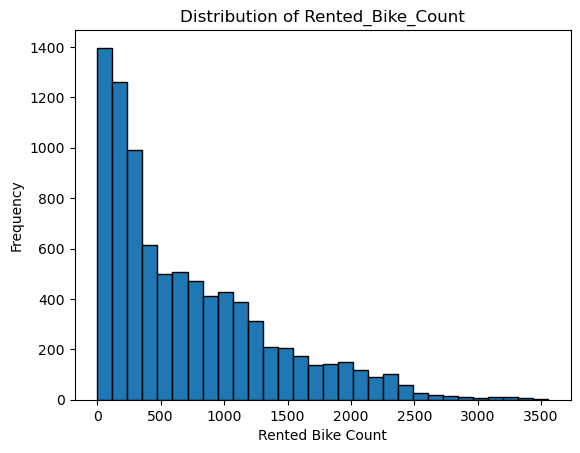

In [43]:
# Settle the missing numerical columns first if any by checking the distribution
# Plotting a histogram for 'Rented_Bike_Count' 
# If the histogram is bell-shaped, it’s a sign of normal distribution.
# If it’s skewed (long tail) to the left or right, it indicates the presence of outliers.

import matplotlib.pyplot as plt

df_new['Rented_Bike_Count'].plot(kind='hist', bins=30, edgecolor='black')
plt.title('Distribution of Rented_Bike_Count')
plt.xlabel('Rented Bike Count')
plt.show()

C:\Users\user\AppData\Local\Temp\ipykernel_27128\2377528984.py:6: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(df_new['Rented_Bike_Count'].dropna(), shade=True)


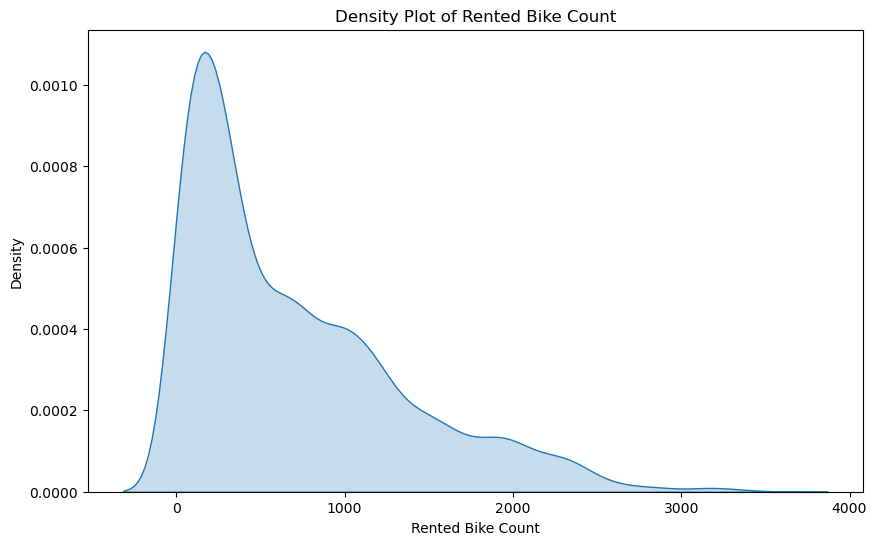

In [44]:
# Visualizing the density distribution using seaborn library
import seaborn as sns

# Density plot of Bike Rental 
plt.figure(figsize=(10, 6))
sns.kdeplot(df_new['Rented_Bike_Count'].dropna(), shade=True)
plt.title('Density Plot of Rented Bike Count')
plt.xlabel('Rented Bike Count')
plt.show()

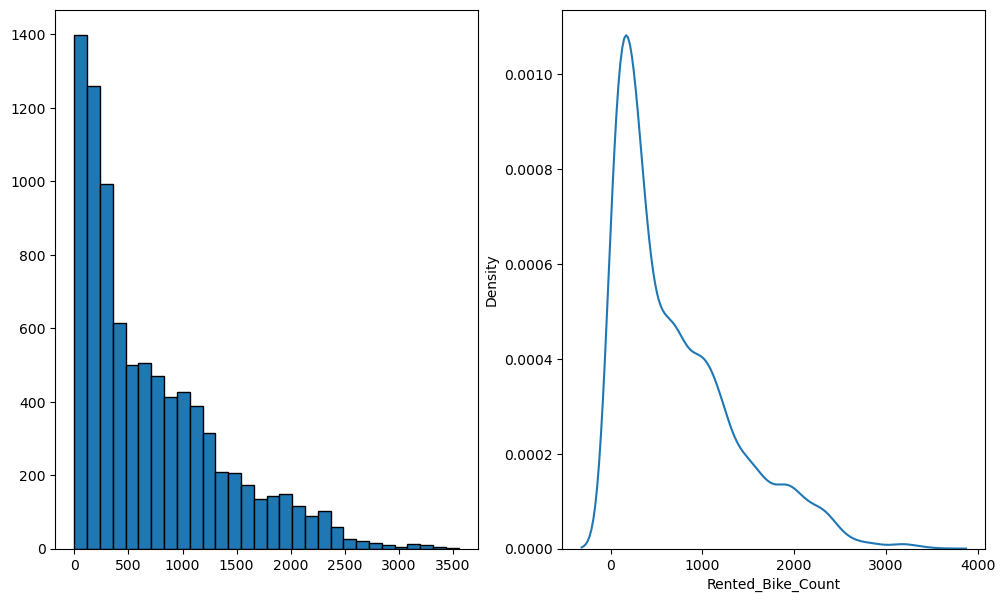

In [45]:
# Combining them together side by side
plt.figure(figsize=(12,7))

# histo first
plt.subplot(1,2,1) # 1 means , two image in 1 row, for 2 columns, 1 means left, 2 means right
plt.hist(x=df_new['Rented_Bike_Count'],bins=30, edgecolor='#000000') # have bins

plt.subplot(1,2,2)
sns.kdeplot(x=df_new['Rented_Bike_Count'])
plt.show()

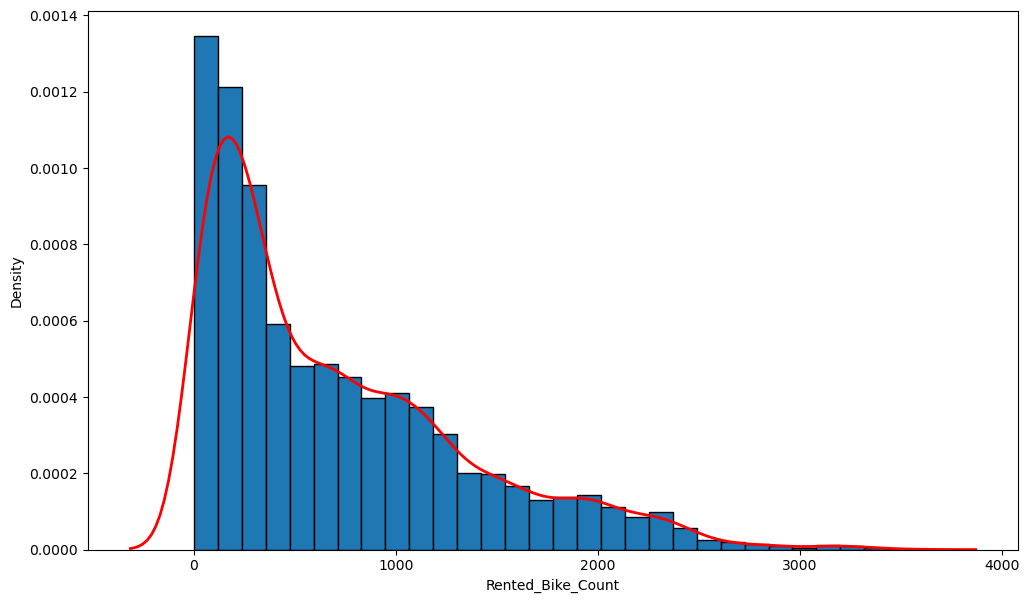

In [46]:
# Overlapping them on top of one another
plt.figure(figsize=(12,7))

#histo first

plt.hist(x=df_new['Rented_Bike_Count'],bins=30, edgecolor='#000000',density=True) # have bins

sns.kdeplot(x=df_new['Rented_Bike_Count'], linewidth=2,color='red')
plt.show()

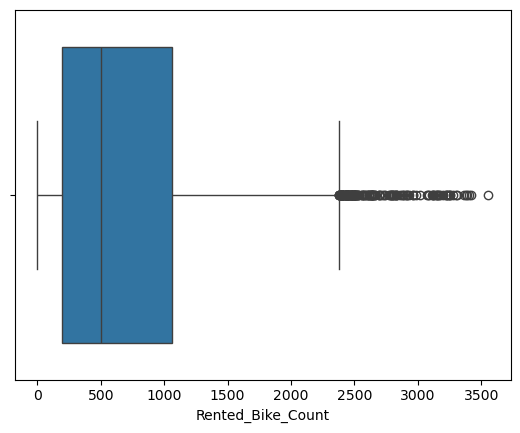

In [47]:
# Reviewing the boxplot to check for skew distribution

sns.boxplot(x=df_new['Rented_Bike_Count'])
plt.show()

In [48]:
# Checking skew level
# as long not withint -1 < x < 1 , then not normally distributed
df_new['Rented_Bike_Count'].skew() 

np.float64(1.1534281773679014)

In [49]:
# Checking it with other numbers
df_new['Rented_Bike_Count'].describe()

# if it is normally distributed, Mean = Median

count    8760.000000
mean      704.602055
std       644.997468
min         0.000000
25%       191.000000
50%       504.500000
75%      1065.250000
max      3556.000000
Name: Rented_Bike_Count, dtype: float64

In [50]:
# Summary statistics for numerical columns
# Compare mean and median
mean_Bike_Rental = df_new['Rented_Bike_Count'].mean()
median_Bike_Rental = df_new['Rented_Bike_Count'].median()

print(f"Mean Rented_Bike_Count: {mean_Bike_Rental}")
print(f"Median Rented_Bike_Count: {median_Bike_Rental}")

Mean Rented_Bike_Count: 704.6020547945205
Median Rented_Bike_Count: 504.5


In [52]:
# Before substituting, check how many missing values are there 
df_new['Rented_Bike_Count'].isnull().sum()

# --------------------------------------------------------------------------------------------
# If there are missing values, replace with mean/median
# Normally replacing with median values for skewed data
# df_new['Rented_Bike_Count'].fillna(df_new['Rented_Bike_Count'].median(), inplace=True)
#df_new['Rented_Bike_Count'].isnull().sum()

np.int64(0)

In [53]:
# Step 6 : remove/trim the outliers
# Check for top 1% or 99th percentile first usually
df_new['Rented_Bike_Count'].quantile(0.99) # top 1% outlier 

np.float64(2526.2299999999996)

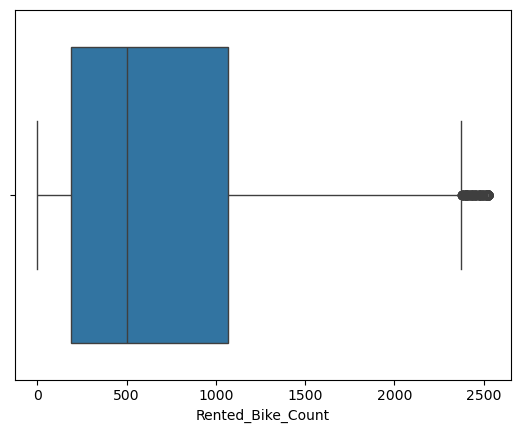

In [54]:
# Removing step 1: create a copy of the original DataFrame, always do this to ensure you wont lose the original dataframe
df_new_1 = df_new.copy()

# Removing step 2: clip 'Rented_Bike_Count' column at the 99th percentile (top 1% outliers)
df_new_1['Rented_Bike_Count'] = df_new['Rented_Bike_Count'].clip(upper=df_new['Rented_Bike_Count'].quantile(0.99))

# Removing step step 3: Plot the boxplot to visualize 'Rented_Bike_Count' after clipping
sns.boxplot(x=df_new_1['Rented_Bike_Count'])

# Show the plot
plt.show()

In [58]:
# Then checking the skewness if it is within a good range
df_new_1['Rented_Bike_Count'].skew()

np.float64(1.0409988669760633)

In [56]:
# Checking with the original how much skewness has been reduced
df_new['Rented_Bike_Count'].skew() # check with original

np.float64(1.1534281773679014)

In [59]:
# Then, validating by checking the skewness and kurtosis
skewness = df_new_1['Rented_Bike_Count'].skew()
kurtosis = df_new_1['Rented_Bike_Count'].kurt()

print(f"Skewness: {skewness}")
print(f"Kurtosis: {kurtosis}")

Skewness: 1.0409988669760633
Kurtosis: 0.2848876081043974


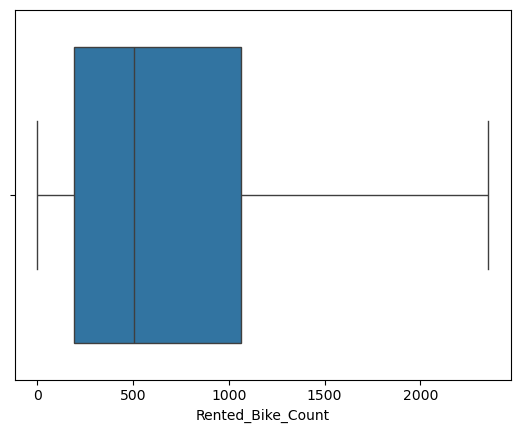

In [263]:
# Not satisfied, cliping further by another top 2% or 98th percentile

# Removing step1 : create another copy of the original DataFrame
df_new_2 = df_new_1.copy()

# Removing step 2:  clip 'Rented_Bike_Count' column at the 98th percentile (top 2% outliers)
df_new_2['Rented_Bike_Count'] = df_new_1['Rented_Bike_Count'].clip(upper=df_new_1['Rented_Bike_Count'].quantile(0.98))

# Removing step 3: plot the boxplot to visualize it after clipping
sns.boxplot(x=df_new_2['Rented_Bike_Count'])

# Show the plot
plt.show()

In [264]:
# check and see 
skewness = df_new_2['Rented_Bike_Count'].skew()
kurtosis = df_new_2['Rented_Bike_Count'].kurt()

print(f"Skewness: {skewness}")
print(f"Kurtosis: {kurtosis}") 

# -----------------------------------------------------------------------------------------------------------------------
# If it is still NOT satisfactory, try clipping it max 95th percentile but not recommended you lose a lot of info

# Skewness	Interpretation
# ~0 : symmetric
# 0.5 to 1 : moderately skewed
# > 1 : highly skewed

Skewness: 0.9965154916653709
Kurtosis: 0.11089299533880048


Skewness after log transformation: -1.8452348919960544
Kurtosis after log transformation: 4.371098172694692


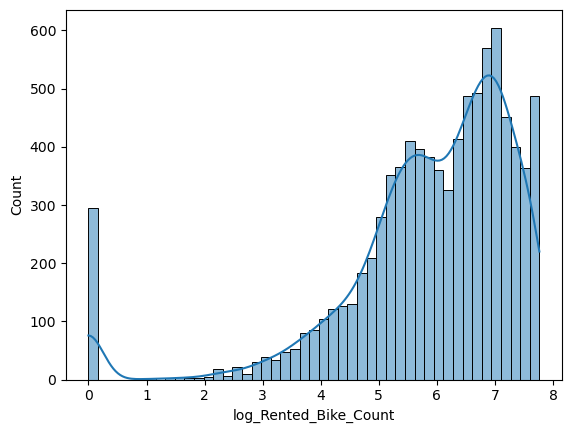

In [265]:
# Apply log transformation after clipping at 98th percentile
# bettwe to log it after clipping 
df_new_2['log_Rented_Bike_Count'] = np.log(df_new_2['Rented_Bike_Count'] + 1)  # +1 to avoid log(0)

# Check skewness and kurtosis after log transformation
skewness_log = df_new_2['log_Rented_Bike_Count'].skew()
kurtosis_log = df_new_2['log_Rented_Bike_Count'].kurt()

print(f"Skewness after log transformation: {skewness_log}")
print(f"Kurtosis after log transformation: {kurtosis_log}")

# Visualize the distribution of the log-transformed prices
sns.histplot(df_new_2['log_Rented_Bike_Count'], kde=True)
plt.show()

In [266]:
# Check how many missing values to impute
df_new_2.isnull().sum()

Date                       0
Rented_Bike_Count          0
Hour                       0
Temperature                0
Humidity(%)                0
Wind_speed(m/s)            0
Visibility_(10m)           0
Solar_Radiation(MJ/m2)     0
Rainfall(mm)               0
Snowfall(cm)               0
Seasons                   56
Holiday                    0
Functioning_Day            0
Hour_sin                   0
Hour_cos                   0
log_Rented_Bike_Count      0
dtype: int64

In [267]:
# All Numerical missing columns finished filling
# Now going with categorical columns

# Fill missing Seasons based on Date using grouped mode
# Since each date should belong to one season, Date is a logical reference variable.
# One date belongs to only one season.

season_mapping = (
    df_new_2.groupby('Date')['Seasons']
    .agg(lambda x: x.dropna().mode().iloc[0] if not x.dropna().mode().empty else np.nan)
    .to_dict()
)

season_mapping

{Timestamp('2017-12-01 00:00:00'): 'Winter',
 Timestamp('2017-12-02 00:00:00'): 'Winter',
 Timestamp('2017-12-03 00:00:00'): 'Winter',
 Timestamp('2017-12-04 00:00:00'): 'Winter',
 Timestamp('2017-12-05 00:00:00'): 'Winter',
 Timestamp('2017-12-06 00:00:00'): 'Winter',
 Timestamp('2017-12-07 00:00:00'): 'Winter',
 Timestamp('2017-12-08 00:00:00'): 'Winter',
 Timestamp('2017-12-09 00:00:00'): 'Winter',
 Timestamp('2017-12-10 00:00:00'): 'Winter',
 Timestamp('2017-12-11 00:00:00'): 'Winter',
 Timestamp('2017-12-12 00:00:00'): 'Winter',
 Timestamp('2017-12-13 00:00:00'): 'Winter',
 Timestamp('2017-12-14 00:00:00'): 'Winter',
 Timestamp('2017-12-15 00:00:00'): 'Winter',
 Timestamp('2017-12-16 00:00:00'): 'Winter',
 Timestamp('2017-12-17 00:00:00'): 'Winter',
 Timestamp('2017-12-18 00:00:00'): 'Winter',
 Timestamp('2017-12-19 00:00:00'): 'Winter',
 Timestamp('2017-12-20 00:00:00'): 'Winter',
 Timestamp('2017-12-21 00:00:00'): 'Winter',
 Timestamp('2017-12-22 00:00:00'): 'Winter',
 Timestamp

In [268]:
# Since the output too long, just checking if there are any NaN values
# IF result returns False means, OK no problem

# Check if any NaN values exist in the model_mapping dictionary
contains_nan = any(pd.isna(value) for value in season_mapping.values())

# Output the result
print("Does season_mapping contain NaN values?", contains_nan)

Does season_mapping contain NaN values? False


In [269]:
# How to know if enough features, checking correlation
# Create a new column indicating whether 'Seasons' is missing (1 if missing, 0 if not)
df_new_2['season_missing'] = df_new_2['Seasons'].isnull().astype(int)
df_new_2

,Date,Rented_Bike_Count,Hour,Temperature,Humidity(%),Wind_speed(m/s),Visibility_(10m),Solar_Radiation(MJ/m2),Rainfall(mm),Snowfall(cm),Seasons,Holiday,Functioning_Day,Hour_sin,Hour_cos,log_Rented_Bike_Count,season_missing
0,2017-12-01,254.0,0,-5.2,37,2.2,2000,0.73,0.0,0.0,Winter,No Holiday,Yes,0.000000,1.000000,5.541264,0
1,2017-12-01,204.0,1,-5.5,38,0.8,2000,0.73,0.0,0.0,Winter,No Holiday,Yes,0.258819,0.965926,5.323010,0
2,2017-12-01,173.0,2,-6.0,39,1.0,2000,0.73,0.0,0.0,Winter,No Holiday,Yes,0.500000,0.866025,5.159055,0
3,2017-12-01,107.0,3,-6.2,40,0.9,2000,0.73,0.0,0.0,Winter,No Holiday,Yes,0.707107,0.707107,4.682131,0
4,2017-12-01,78.0,4,-6.0,36,2.3,2000,0.73,0.0,0.0,Winter,No Holiday,Yes,0.866025,0.500000,4.369448,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,2018-11-30,1003.0,19,4.2,34,2.6,1894,0.03,0.0,0.0,Autumn,No Holiday,Yes,-0.965926,0.258819,6.911747,0
8756,2018-11-30,764.0,20,3.4,37,2.3,2000,0.73,0.0,0.0,Autumn,No Holiday,Yes,-0.866025,0.500000,6.639876,0
8757,2018-11-30,694.0,21,2.6,39,0.3,1968,0.73,0.0,0.0,Autumn,No Holiday,Yes,-0.707107,0.707107,6.543912,0
8758,2018-11-30,712.0,22,2.1,41,1.0,1859,0.73,0.0,0.0,Autumn,No Holiday,Yes,-0.500000,0.866025,6.569481,0


In [270]:
# Correlation of missing model indicator with other numerical features
correlations = df_new_2[['season_missing', 'Date', 'Temperature', 'Humidity(%)', 'Visibility_(10m)','Solar_Radiation(MJ/m2)']].corr()

# Display the correlations between 'model_missing' and the other features
correlations['season_missing']

season_missing            1.000000
Date                     -0.010902
Temperature              -0.005534
Humidity(%)              -0.005816
Visibility_(10m)          0.009032
Solar_Radiation(MJ/m2)   -0.016889
Name: season_missing, dtype: float64

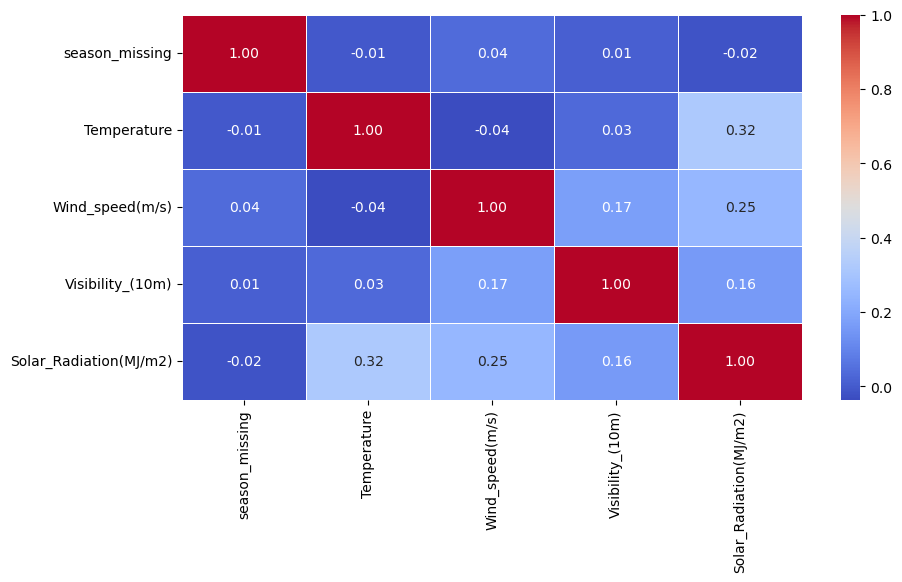

In [271]:
# We can use Heat Map for better visualization
# put every variable you wana check in a colum 
plt.figure(figsize=(10,5))


corr_mat=correlations = df_new_2[['season_missing', 'Temperature', 'Wind_speed(m/s)', 'Visibility_(10m)', 'Solar_Radiation(MJ/m2)']].corr()

#heatmap for better visual , so darker red means 1, lighter color no relation
sns.heatmap(corr_mat,annot=True,linewidths=0.5,fmt='.2f',cmap="coolwarm")
plt.show()

In [272]:
# just now correlation only check for numerical values, what about categorical, can use mean method
# Proportion of missing 'season' for each category in 'Date' 
hour_missing_proportion = df_new_2.groupby('Date')['season_missing'].mean().apply(lambda x: f"{x * 100:.5f}%")


# Display results
print(hour_missing_proportion)

# Guidelines for Interpreting Proportions:
# Very Weak Relationship (< 0.05):

# If the proportion of missing values is below 5% (0.05) for all categories, this suggests a weak relationship. In your case, all proportions are far below 0.05, indicating a weak or negligible relationship between model missingness and the fuelType or transmission categories.
# Moderate Relationship (0.05 - 0.10):

# If the proportion of missing values falls between 5% and 10%, it might suggest a moderate relationship. A proportion in this range could be considered non-random, but still not very strong. None of the categories in your data reach this threshold.
# Strong Relationship (> 0.10):

# If the proportion exceeds 10% (0.10), there may be a strong relationship between the missing values and the category. This would imply that being in a particular category significantly increases the likelihood of missing data.

Date
2017-12-01    8.33333%
2017-12-02    4.16667%
2017-12-03    4.16667%
2017-12-04    8.33333%
2017-12-05    4.16667%
                ...   
2018-11-26    0.00000%
2018-11-27    0.00000%
2018-11-28    0.00000%
2018-11-29    0.00000%
2018-11-30    0.00000%
Name: season_missing, Length: 365, dtype: object


In [273]:
df_new_2.dtypes

Date                      datetime64[ns]
Rented_Bike_Count                float64
Hour                               int64
Temperature                      float64
Humidity(%)                        int64
Wind_speed(m/s)                  float64
Visibility_(10m)                   int64
Solar_Radiation(MJ/m2)           float64
Rainfall(mm)                     float64
Snowfall(cm)                     float64
Seasons                           object
Holiday                           object
Functioning_Day                   object
Hour_sin                         float64
Hour_cos                         float64
log_Rented_Bike_Count            float64
season_missing                     int64
dtype: object

In [274]:
# And proceed with substituting our missing categorical values with the mapping mode above
# df_new_2["Seasons"] = df_new_2.apply(lambda row: season_mapping_all.get((row['Hour'],row['Holiday']),row['Seasons']), axis=1)

# Create mapping by Date
season_mapping = (
    df_new_2.groupby(['Date'])['Seasons']
    .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan)
    .to_dict()
)

# Fill missing Seasons using Date mapping
df_new_2["Seasons"] = df_new_2.apply(
    lambda row: season_mapping.get(row['Date'], row['Seasons'])
    if pd.isna(row['Seasons']) else row['Seasons'],
    axis=1
)

df_new_2

,Date,Rented_Bike_Count,Hour,Temperature,Humidity(%),Wind_speed(m/s),Visibility_(10m),Solar_Radiation(MJ/m2),Rainfall(mm),Snowfall(cm),Seasons,Holiday,Functioning_Day,Hour_sin,Hour_cos,log_Rented_Bike_Count,season_missing
0,2017-12-01,254.0,0,-5.2,37,2.2,2000,0.73,0.0,0.0,Winter,No Holiday,Yes,0.000000,1.000000,5.541264,0
1,2017-12-01,204.0,1,-5.5,38,0.8,2000,0.73,0.0,0.0,Winter,No Holiday,Yes,0.258819,0.965926,5.323010,0
2,2017-12-01,173.0,2,-6.0,39,1.0,2000,0.73,0.0,0.0,Winter,No Holiday,Yes,0.500000,0.866025,5.159055,0
3,2017-12-01,107.0,3,-6.2,40,0.9,2000,0.73,0.0,0.0,Winter,No Holiday,Yes,0.707107,0.707107,4.682131,0
4,2017-12-01,78.0,4,-6.0,36,2.3,2000,0.73,0.0,0.0,Winter,No Holiday,Yes,0.866025,0.500000,4.369448,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,2018-11-30,1003.0,19,4.2,34,2.6,1894,0.03,0.0,0.0,Autumn,No Holiday,Yes,-0.965926,0.258819,6.911747,0
8756,2018-11-30,764.0,20,3.4,37,2.3,2000,0.73,0.0,0.0,Autumn,No Holiday,Yes,-0.866025,0.500000,6.639876,0
8757,2018-11-30,694.0,21,2.6,39,0.3,1968,0.73,0.0,0.0,Autumn,No Holiday,Yes,-0.707107,0.707107,6.543912,0
8758,2018-11-30,712.0,22,2.1,41,1.0,1859,0.73,0.0,0.0,Autumn,No Holiday,Yes,-0.500000,0.866025,6.569481,0


In [275]:
# One final check to see if this time, everything is 0
df_new_2.isnull().sum()

Date                      0
Rented_Bike_Count         0
Hour                      0
Temperature               0
Humidity(%)               0
Wind_speed(m/s)           0
Visibility_(10m)          0
Solar_Radiation(MJ/m2)    0
Rainfall(mm)              0
Snowfall(cm)              0
Seasons                   0
Holiday                   0
Functioning_Day           0
Hour_sin                  0
Hour_cos                  0
log_Rented_Bike_Count     0
season_missing            0
dtype: int64

In [276]:
# Get numerical columns using select_dtypes for 'number' types (int64, float64)
numerical_columns = df_new_2.select_dtypes('number').columns.to_list()

# Get categorical columns by excluding the numerical ones
categorical_columns = df_new_2.select_dtypes(exclude='number').columns.to_list()

# Count how many columns are numerical and categorical
num_numerical = len(numerical_columns)
num_categorical = len(categorical_columns)

# Print the results
print(f"Numerical columns: {numerical_columns}")
print(f"Categorical columns: {categorical_columns}")

Numerical columns: ['Rented_Bike_Count', 'Hour', 'Temperature', 'Humidity(%)', 'Wind_speed(m/s)', 'Visibility_(10m)', 'Solar_Radiation(MJ/m2)', 'Rainfall(mm)', 'Snowfall(cm)', 'Hour_sin', 'Hour_cos', 'log_Rented_Bike_Count', 'season_missing']
Categorical columns: ['Date', 'Seasons', 'Holiday', 'Functioning_Day']


In [277]:
# Encode categorical variables for ML

# Categorials should be converted into numerical representations before training

# 1. Clean text values first
# Remove extra spaces from categorical columns
df_new_2['Seasons'] = df_new_2['Seasons'].astype(str).str.strip()
df_new_2['Holiday'] = df_new_2['Holiday'].astype(str).str.strip()
df_new_2['Functioning_Day'] = df_new_2['Functioning_Day'].astype(str).str.strip()

# 2. One-hot encode Seasons
# drop_first=True removes one baseline category to avoid multicollinearity.
season_dummies = pd.get_dummies(
    df_new_2['Seasons'],
    prefix='Seasons',
    drop_first=True
)

# Concatenate dummy columns while keeping original Seasons column
# Original Seasons is kept for inspection/visualization,
# but should be dropped before model training.
df_new_2 = pd.concat([df_new_2, season_dummies], axis=1)

# 3. Binary encode Holiday
# 0 = No Holiday, # 1 = Holiday
df_new_2['Holiday'] = df_new_2['Holiday'].map({
    'No Holiday': 0,
    'Holiday': 1
})

# 4. Binary encode Functioning_Day
# 0 = Non-functioning day, 1 = Functioning day
df_new_2['Functioning_Day'] = df_new_2['Functioning_Day'].map({
    'No': 0,
    'Yes': 1
})

# 5. Create weekend-related feature
# Convert Date to datetime format
df_new_2['Date'] = pd.to_datetime(df_new_2['Date'])

# Extract day of week
# Monday = 0, Sunday = 6
df_new_2['DayOfWeek'] = df_new_2['Date'].dt.dayofweek

# Create Weekend variable
# 0 = Weekday, 1 = Weekend
df_new_2['Weekend'] = df_new_2['DayOfWeek'].apply(
    lambda x: 1 if x >= 5 else 0
)
# 6. Check whether encoding created missing values
print(df_new_2[['Holiday', 'Functioning_Day', 'Weekend']].isnull().sum())

Holiday            0
Functioning_Day    0
Weekend            0
dtype: int64


In [279]:
# Check how many missing values to impute
df_new_2.isnull().sum()

Date                      0
Rented_Bike_Count         0
Hour                      0
Temperature               0
Humidity(%)               0
Wind_speed(m/s)           0
Visibility_(10m)          0
Solar_Radiation(MJ/m2)    0
Rainfall(mm)              0
Snowfall(cm)              0
Seasons                   0
Holiday                   0
Functioning_Day           0
Hour_sin                  0
Hour_cos                  0
log_Rented_Bike_Count     0
season_missing            0
Seasons_Spring            0
Seasons_Summer            0
Seasons_Winter            0
DayOfWeek                 0
Weekend                   0
dtype: int64

In [281]:
df_new_2.head()

,Date,Rented_Bike_Count,Hour,Temperature,Humidity(%),Wind_speed(m/s),Visibility_(10m),Solar_Radiation(MJ/m2),Rainfall(mm),Snowfall(cm),...,Functioning_Day,Hour_sin,Hour_cos,log_Rented_Bike_Count,season_missing,Seasons_Spring,Seasons_Summer,Seasons_Winter,DayOfWeek,Weekend
0,2017-12-01,254.0,0,-5.2,37,2.2,2000,0.73,0.0,0.0,...,1,0.000000,1.000000,5.541264,0,False,False,True,4,0
1,2017-12-01,204.0,1,-5.5,38,0.8,2000,0.73,0.0,0.0,...,1,0.258819,0.965926,5.323010,0,False,False,True,4,0
2,2017-12-01,173.0,2,-6.0,39,1.0,2000,0.73,0.0,0.0,...,1,0.500000,0.866025,5.159055,0,False,False,True,4,0
3,2017-12-01,107.0,3,-6.2,40,0.9,2000,0.73,0.0,0.0,...,1,0.707107,0.707107,4.682131,0,False,False,True,4,0
4,2017-12-01,78.0,4,-6.0,36,2.3,2000,0.73,0.0,0.0,...,1,0.866025,0.500000,4.369448,0,False,False,True,4,0


In [282]:
print(df_new_2[['Holiday', 'Functioning_Day']].isnull().sum())
print(df_new_2['Holiday'].value_counts())

Holiday            0
Functioning_Day    0
dtype: int64
Holiday
0    8328
1     432
Name: count, dtype: int64


2. Machine Learning Analysis

In [327]:
# The goal of this analysis is to predict the number of rented bikes.

# Separate predictors (X) and target variable (y).
# Target variable:
# - Rented_Bike_Count is the value we want to predict.
# - It must be removed from X to avoid data leakage.

# Columns removed from X:
# - Rented_Bike_Count: target variable
# - Date: raw date is not directly used for ML here
# - Hour: removed because Hour_sin and Hour_cos already represent time cyclically
# - season_missing: auxiliary preprocessing column, not needed for modeling

X = df_new_2.drop(columns=[
    "Rented_Bike_Count",
    "Date",
    "Hour",
    "season_missing",
    "log_Rented_Bike_Count"
])

# Target variable
y = df_new_2["Rented_Bike_Count"]

In [329]:
 # Step 1: Explore categorical variables

# Display unique values in the Seasons column
# This helps us understand the categories present in the dataset
print(df_new_2['Seasons'].unique())

# Count the number of unique categories
# Useful for deciding how to encode categorical variables for ML
print('No. of unique values:', df_new_2['Seasons'].nunique())

['Winter' 'Spring' 'Summer' 'Autumn']
No. of unique values: 4


In [366]:
# Feature Engineering

# Create additional time-related features from Date
# These features may help capture temporal rental patterns

# Convert Date column to datetime format
df_new_2['Date'] = pd.to_datetime(df_new_2['Date'])

# Extract month
# Bike rental demand may vary by season/month
df_new_2['Month'] = df_new_2['Date'].dt.month

# Extract day of week
# Weekdays and weekends often show different rental patterns
df_new_2['DayOfWeek'] = df_new_2['Date'].dt.dayofweek

# Create weekend indicator
# 1 = Weekend, 0 = Weekday
df_new_2['Weekend'] = (
    df_new_2['DayOfWeek']
    .apply(lambda x: 1 if x >= 5 else 0)
)

# Update X
X = df_new_2.drop(columns=[
    "Rented_Bike_Count",
    "Date",
    "Hour",
    "season_missing",
    "log_Rented_Bike_Count"
])

df_new_2.head()

,Date,Rented_Bike_Count,Hour,Temperature,Humidity(%),Wind_speed(m/s),Visibility_(10m),Solar_Radiation(MJ/m2),Rainfall(mm),Snowfall(cm),...,Hour_sin,Hour_cos,log_Rented_Bike_Count,season_missing,Seasons_Spring,Seasons_Summer,Seasons_Winter,DayOfWeek,Weekend,Month
0,2017-12-01,254.0,0,-5.2,37,2.2,2000,0.73,0.0,0.0,...,0.000000,1.000000,5.541264,0,False,False,True,4,0,12
1,2017-12-01,204.0,1,-5.5,38,0.8,2000,0.73,0.0,0.0,...,0.258819,0.965926,5.323010,0,False,False,True,4,0,12
2,2017-12-01,173.0,2,-6.0,39,1.0,2000,0.73,0.0,0.0,...,0.500000,0.866025,5.159055,0,False,False,True,4,0,12
3,2017-12-01,107.0,3,-6.2,40,0.9,2000,0.73,0.0,0.0,...,0.707107,0.707107,4.682131,0,False,False,True,4,0,12
4,2017-12-01,78.0,4,-6.0,36,2.3,2000,0.73,0.0,0.0,...,0.866025,0.500000,4.369448,0,False,False,True,4,0,12


In [367]:
# Check the distribution of Weekend values
# 0 = Weekday, 1 = Weekend
df_new_2['Weekend'].value_counts()

Weekend
0    6264
1    2496
Name: count, dtype: int64

In [368]:
# Check the distribution of Seasons
df_new_2['Seasons'].value_counts()

Seasons
Spring    2208
Summer    2208
Autumn    2184
Winter    2160
Name: count, dtype: int64

In [369]:
# Calculate the percentage of Weekend values
# 0 = Weekday, 1 = Weekend
weekend_percentage = X['Weekend'].value_counts(normalize=True) * 100

# Format percentages with '%' sign
weekend_percentage = weekend_percentage.round(2).astype(str) + '%'


# Calculate the percentage distribution of Seasons
season_percentage = df_new_2['Seasons'].value_counts(normalize=True) * 100

# Format percentages with '%' sign
season_percentage = season_percentage.round(2).astype(str) + '%'

# Display the result
print(weekend_percentage)
print(season_percentage)

Weekend
0    71.51%
1    28.49%
Name: proportion, dtype: object
Seasons
Spring    25.21%
Summer    25.21%
Autumn    24.93%
Winter    24.66%
Name: proportion, dtype: object


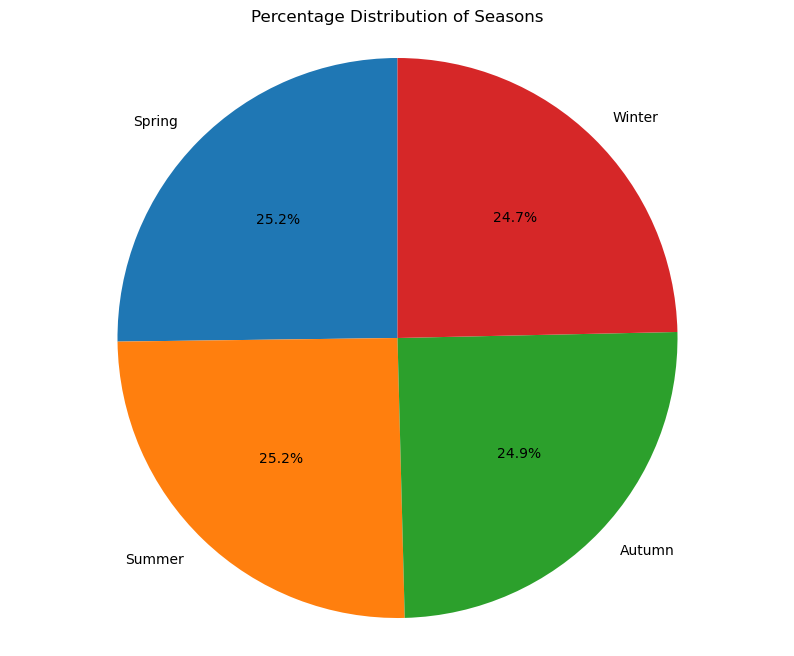

In [370]:
# Pie Chart: Distribution of Seasons

plt.figure(figsize=(10, 8))

plt.pie(
    df_new_2['Seasons'].value_counts(),
    labels=df_new_2['Seasons'].value_counts().index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Percentage Distribution of Seasons')

# Ensures pie chart is circular
plt.axis('equal')

plt.show()

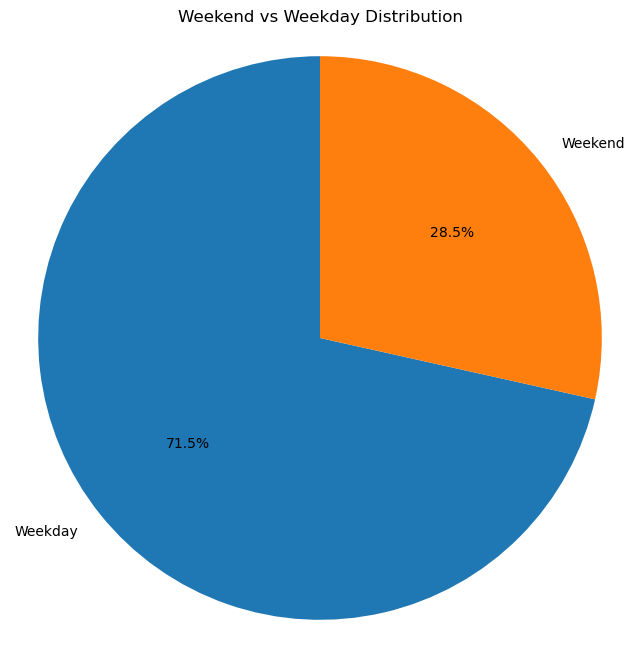

In [371]:
# Pie Chart: Weekend vs Weekday

plt.figure(figsize=(8, 8))

plt.pie(
    df_new_2['Weekend'].value_counts(),
    labels=['Weekday', 'Weekend'],
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Weekend vs Weekday Distribution')
plt.axis('equal')

plt.show()

C:\Users\user\AppData\Local\Temp\ipykernel_27128\3242507383.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


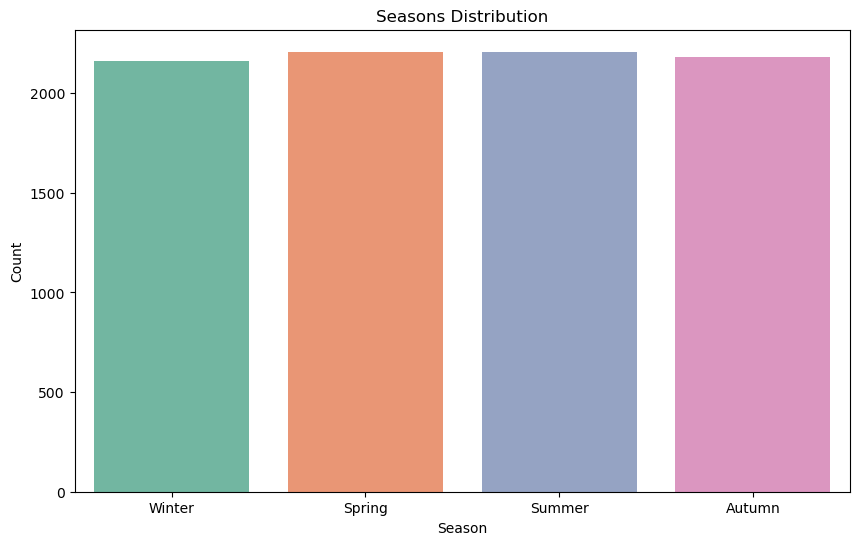

In [372]:
# Count Plot: Seasons Distribution

plt.figure(figsize=(10, 6))

sns.countplot(
    data=df_new_2,
    x='Seasons',
    palette='Set2'
)

plt.title('Seasons Distribution')
plt.xlabel('Season')
plt.ylabel('Count')

plt.show()

C:\Users\user\AppData\Local\Temp\ipykernel_27128\927716070.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


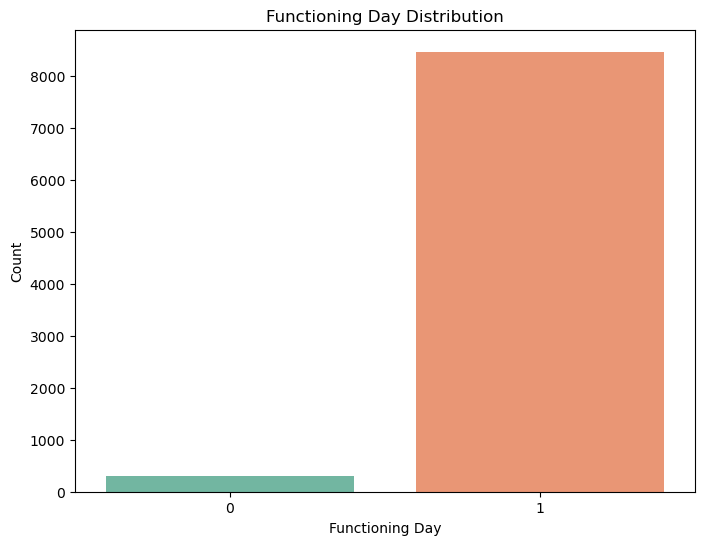

In [373]:
# Count Plot: Functioning Day Distribution

plt.figure(figsize=(8, 6))

sns.countplot(
    data=df_new_2,
    x='Functioning_Day',
    palette='Set2'
)

plt.title('Functioning Day Distribution')
plt.xlabel('Functioning Day')
plt.ylabel('Count')

plt.show()

C:\Users\user\AppData\Local\Temp\ipykernel_27128\1057686927.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


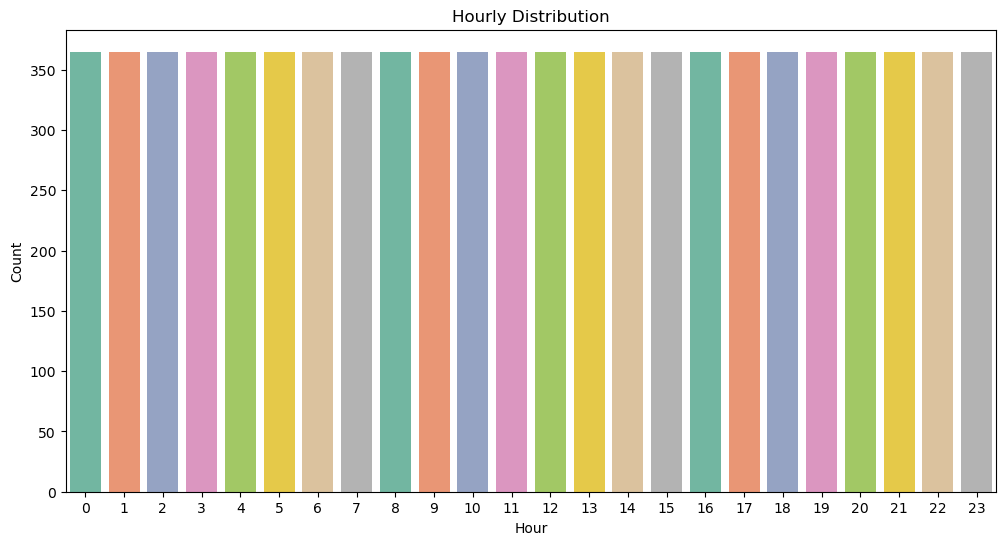

In [374]:
# Bike rentals by hour
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df_new_2,
    x='Hour',
    palette='Set2'
)

plt.title('Hourly Distribution')
plt.xlabel('Hour')
plt.ylabel('Count')

plt.show()

In [375]:
# Check categorical variables before encoding
print(df_new_2[['Seasons', 'Holiday', 'Functioning_Day']].head())

  Seasons  Holiday  Functioning_Day
0  Winter        0                1
1  Winter        0                1
2  Winter        0                1
3  Winter        0                1
4  Winter        0                1


In [376]:
# Check how many missing values to impute
df_new_2.isnull().sum()

Date                      0
Rented_Bike_Count         0
Hour                      0
Temperature               0
Humidity(%)               0
Wind_speed(m/s)           0
Visibility_(10m)          0
Solar_Radiation(MJ/m2)    0
Rainfall(mm)              0
Snowfall(cm)              0
Seasons                   0
Holiday                   0
Functioning_Day           0
Hour_sin                  0
Hour_cos                  0
log_Rented_Bike_Count     0
season_missing            0
Seasons_Spring            0
Seasons_Summer            0
Seasons_Winter            0
DayOfWeek                 0
Weekend                   0
Month                     0
dtype: int64

In [377]:
# Step 3: Feature Scaling
# Scaling helps numerical variables remain within a similar range.

# MinMaxScaler transforms values into the range [0, 1].
# Formula: (x - min) / (max - min)

# Remove original categorical column that containing string
X = X.drop(columns=['Seasons'])

from sklearn.preprocessing import MinMaxScaler

# Initialize scaler
scaler = MinMaxScaler()

# Scale predictor variables
X = pd.DataFrame(
    scaler.fit_transform(X),
    columns=X.columns
)

# Display scaled features
X.head()

,Temperature,Humidity(%),Wind_speed(m/s),Visibility_(10m),Solar_Radiation(MJ/m2),Rainfall(mm),Snowfall(cm),Holiday,Functioning_Day,Hour_sin,Hour_cos,Seasons_Spring,Seasons_Summer,Seasons_Winter,DayOfWeek,Weekend,Month
0,0.220280,0.377551,0.297297,1.0,0.205128,0.0,0.0,0.0,1.0,0.500000,1.000000,0.0,0.0,1.0,0.666667,0.0,1.0
1,0.215035,0.387755,0.108108,1.0,0.205128,0.0,0.0,0.0,1.0,0.629410,0.982963,0.0,0.0,1.0,0.666667,0.0,1.0
2,0.206294,0.397959,0.135135,1.0,0.205128,0.0,0.0,0.0,1.0,0.750000,0.933013,0.0,0.0,1.0,0.666667,0.0,1.0
3,0.202797,0.408163,0.121622,1.0,0.205128,0.0,0.0,0.0,1.0,0.853553,0.853553,0.0,0.0,1.0,0.666667,0.0,1.0
4,0.206294,0.367347,0.310811,1.0,0.205128,0.0,0.0,0.0,1.0,0.933013,0.750000,0.0,0.0,1.0,0.666667,0.0,1.0


In [378]:
# Step 4: Train-Test Split

# Split the dataset into:
# - Training set: used to train the ML model
# - Testing set: used to evaluate model performance


from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25    
)
# test_size=0.25 means:
# - 75% of data used for training
# - 25% of data used for testing

# need to consider 'random_state' is set for reproducibility,so the split remains consistent across runs
# example : random_state=42


# Display training features
X_train.head()

,Temperature,Humidity(%),Wind_speed(m/s),Visibility_(10m),Solar_Radiation(MJ/m2),Rainfall(mm),Snowfall(cm),Holiday,Functioning_Day,Hour_sin,Hour_cos,Seasons_Spring,Seasons_Summer,Seasons_Winter,DayOfWeek,Weekend,Month
8291,0.498252,0.693878,0.054054,0.159149,0.150997,0.0,0.0,0.0,1.0,0.629410,0.017037,0.0,0.0,0.0,1.000000,1.0,0.909091
285,0.157343,0.438776,0.189189,0.999493,0.205128,0.0,0.0,0.0,1.0,0.146447,0.853553,0.0,0.0,1.0,0.166667,0.0,1.000000
8243,0.543706,0.602041,0.554054,0.984795,0.404558,0.0,0.0,0.0,0.0,0.629410,0.017037,0.0,0.0,0.0,0.666667,0.0,0.909091
8539,0.400350,0.510204,0.094595,1.000000,0.005698,0.0,0.0,0.0,1.0,0.017037,0.629410,0.0,0.0,0.0,0.333333,0.0,0.909091
3414,0.566434,0.428571,0.067568,1.000000,0.002849,0.0,0.0,0.0,1.0,1.000000,0.500000,1.0,0.0,0.0,1.000000,1.0,0.272727


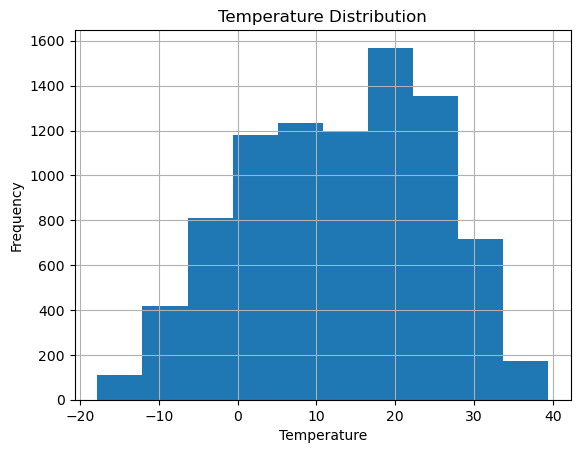

In [379]:
# Check distribution of a numerical variable

# Visualize the distribution of Temperature after preprocessing to ensure the data still retains a reasonable distribution.

df_new_2['Temperature'].hist()

plt.title('Temperature Distribution')
plt.xlabel('Temperature')
plt.ylabel('Frequency')

plt.show()

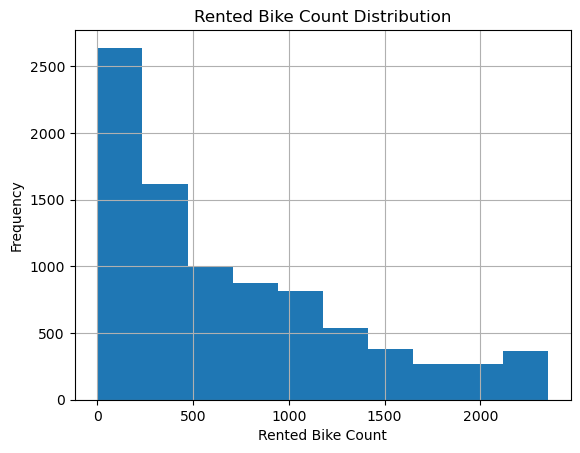

In [380]:
# Distribution of target variable
df_new_2['Rented_Bike_Count'].hist()

plt.title('Rented Bike Count Distribution')
plt.xlabel('Rented Bike Count')
plt.ylabel('Frequency')

plt.show()

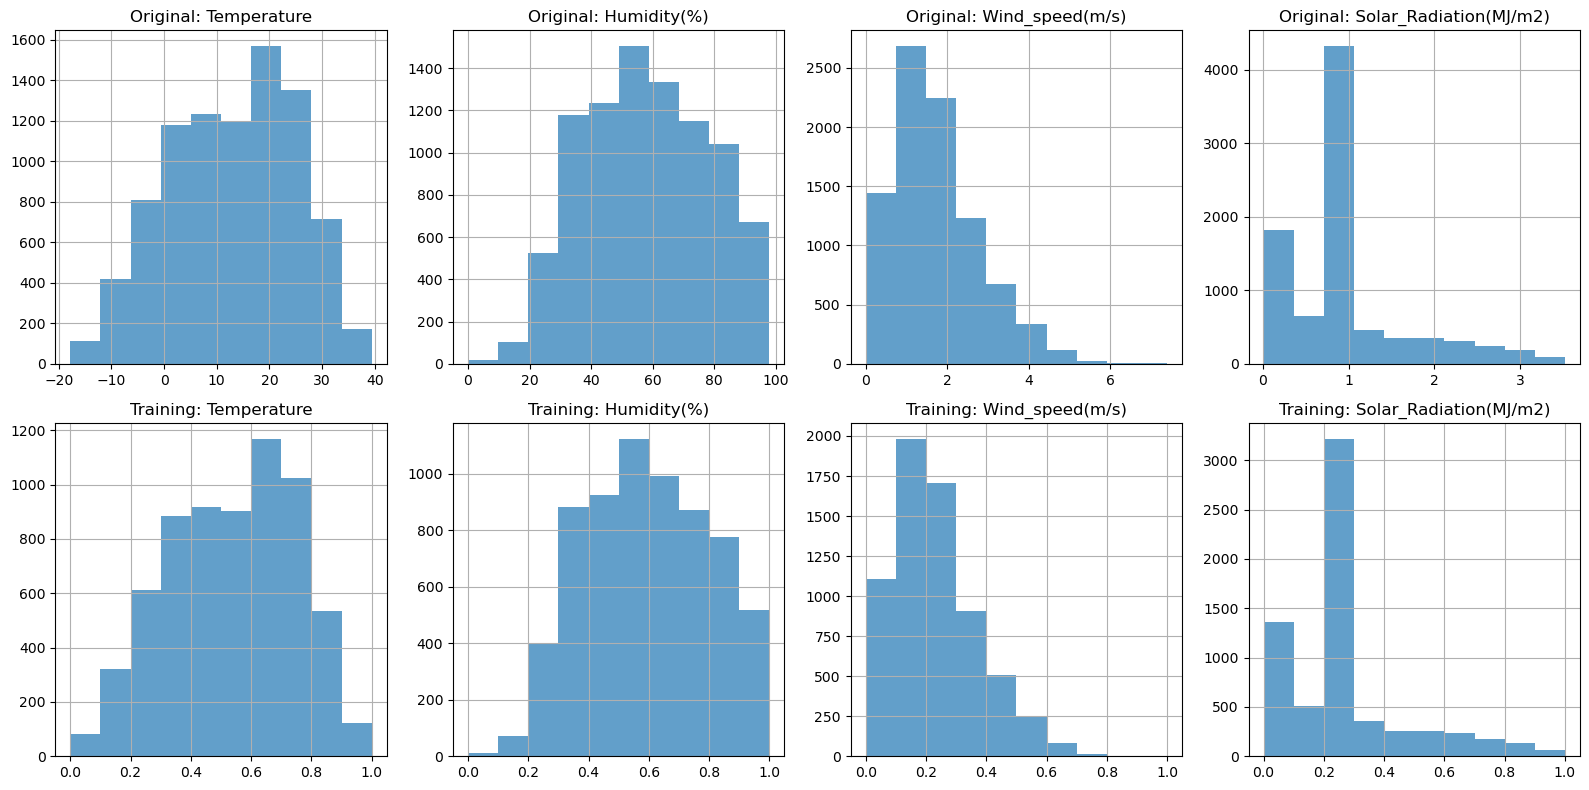

In [381]:
# Compare original and training distributions
# If the original and training distributions are reasonably similar,the train-test split is acceptable.
# If not, need another splitting strategy, such as stratified sampling.

# List of numerical columns to compare
columns_to_compare = [
    'Temperature',
    'Humidity(%)',
    'Wind_speed(m/s)',
    'Solar_Radiation(MJ/m2)'
]

# Set up the subplot grid
# Top row = original data
# Bottom row = training data
fig, axes = plt.subplots(2, len(columns_to_compare), figsize=(16, 8))

for i, column in enumerate(columns_to_compare):
    
    # Original data
    df_new_2[column].hist(ax=axes[0, i], alpha=0.7)
    axes[0, i].set_title(f'Original: {column}')
    
    # Training data
    X_train[column].hist(ax=axes[1, i], alpha=0.7)
    axes[1, i].set_title(f'Training: {column}')

plt.tight_layout()
plt.show()

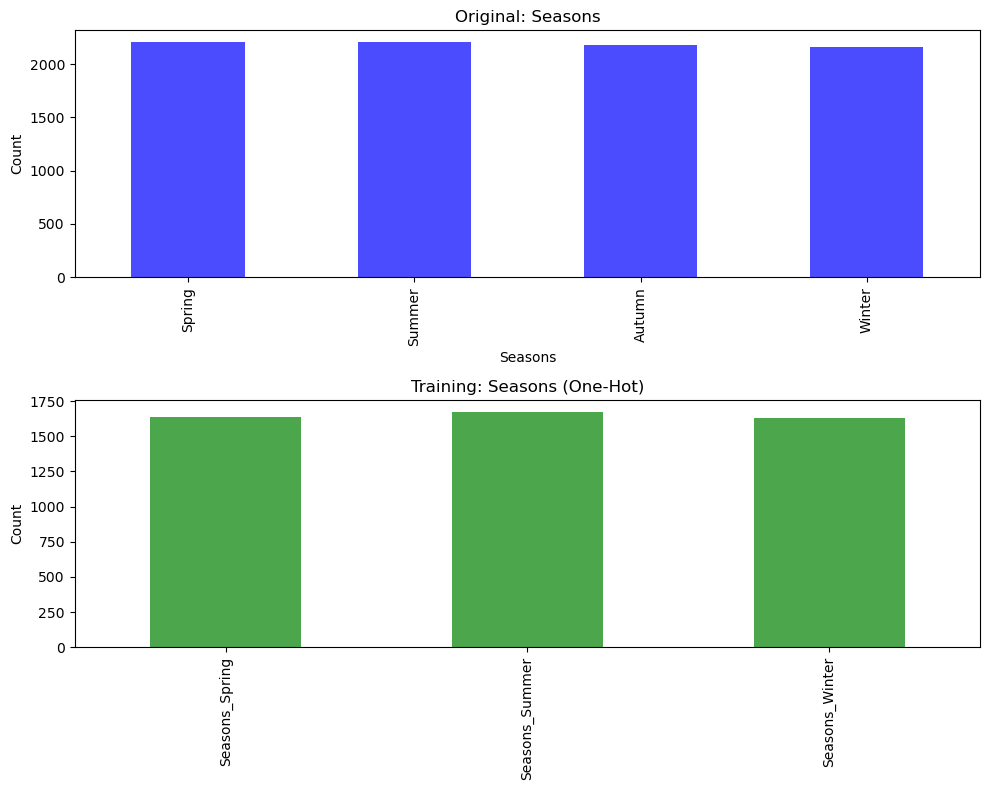

In [382]:
# Compare categorical distributions

# Original categorical columns
categorical_columns = ['Seasons']

# Corresponding one-hot encoded columns
one_hot_columns = [[
    'Seasons_Spring',
    'Seasons_Summer',
    'Seasons_Winter'
]]

# Set up subplot grid
fig, axes = plt.subplots(
    2,
    len(categorical_columns),
    figsize=(10, 8)
)

# If only one categorical column exists, axes becomes 1D, so reshape for consistency
if len(categorical_columns) == 1:
    axes = np.array(axes).reshape(2, 1)

# Loop through categorical variables
for i, column in enumerate(categorical_columns):

    # Original categorical distribution
    df_new_2[column].value_counts().plot(
        kind='bar',
        ax=axes[0, i],
        color='blue',
        alpha=0.7
    )

    axes[0, i].set_title(f'Original: {column}')
    axes[0, i].set_ylabel('Count')

    # One-hot encoded distribution in training data
    X_train[one_hot_columns[i]].sum().plot(
        kind='bar',
        ax=axes[1, i],
        color='green',
        alpha=0.7
    )

    axes[1, i].set_title(f'Training: {column} (One-Hot)')
    axes[1, i].set_ylabel('Count')

# Adjust layout
plt.tight_layout()

plt.show()

In [386]:
# Check which columns still contain missing values
X_train.isnull().sum()[X_train.isnull().sum() > 0]

Series([], dtype: int64)

In [387]:
# Step 5: Machine Learning Model
# Multiple Linear Regression

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

# Create Linear Regression model
linear_regressor = LinearRegression()

# Train the model using training data
linear_regressor.fit(X_train, y_train)

# Predict rented bike count using test data
linear_predictions = linear_regressor.predict(X_test)

# Evaluate model performance using Mean Absolute Error (MAE)
# MAE shows the average prediction error in bike counts
final_mae = mean_absolute_error(y_test, linear_predictions)

print(f'Final MAE on test set: {final_mae}')

# Compare MAE with the average rented bike count
# This helps us understand whether the error is large or small
print(f'Mean rented bike count in test set: {y_test.mean()}')


Final MAE on test set: 318.7220570497262
Mean rented bike count in test set: 702.8383561643835


In [388]:
# Check the average rented bike count in the test dataset
y_test.mean()

# This helps interpret the MAE relative to the typical rental volume

np.float64(702.8383561643835)

In [389]:
# Step 5.1: Perform cross-validation

from sklearn.model_selection import cross_val_score

# The `scoring='neg_mean_absolute_error'` is used because MAE is minimized, 
# and `cross_val_score` maximizes scores. We negate it back to get the positive MAE.
# A Common MISTAKE
cv_scores = cross_val_score(linear_regressor, X, y, cv=5, scoring='neg_mean_absolute_error')

# Step 3: Convert negative scores to positive MAE and calculate the mean MAE
mae_scores = -cv_scores


print(f'MAE scores for each fold: {mae_scores}')
print(f'Cross-validated MAE: {mae_scores.mean()}')

MAE scores for each fold: [389.81715613 346.95032457 501.2812607  545.19083778 309.39659964]
Cross-validated MAE: 418.5272357646434


In [390]:
# Step 5.1: Cross-Validation

from sklearn.model_selection import cross_val_score
# - cv=5 means 5-fold cross-validation
# - The dataset is split into 5 parts
# - The model trains on 4 parts and tests on 1 part repeatedly

# MAE is minimized, but cross_val_score maximizes scores.
# Therefore, sklearn returns negative MAE values.
# We multiply by -1 to convert them back to positive MAE.

cv_scores = cross_val_score(
    linear_regressor,
    X,
    y,
    cv=5,
    scoring='neg_mean_absolute_error'
)

# Convert negative MAE values to positive
mae_scores = -cv_scores

# Display MAE for each fold
print(f'MAE scores for each fold: {mae_scores}')

# Display average cross-validated MAE
print(f'Cross-validated MAE: {mae_scores.mean()}')

MAE scores for each fold: [389.81715613 346.95032457 501.2812607  545.19083778 309.39659964]
Cross-validated MAE: 418.5272357646434


In [391]:
# Step 5.2: Proper Cross-Validation

# Create Linear Regression model
linear_regressor = LinearRegression()

# Perform 5-fold cross-validation on training data
cv_scores1 = cross_val_score(
    linear_regressor,
    X_train,
    y_train,
    cv=5,
    scoring='neg_mean_absolute_error'
)

# sklearn returns negative MAE values because cross_val_score maximizes scores internally.
# Convert them back to positive MAE values.
mae_scores1 = -cv_scores1

# Display MAE for each fold
print(f'MAE scores for each fold: {mae_scores1}')

# Display average cross-validated MAE
print(f'Average cross-validated MAE: {mae_scores1.mean()}')

MAE scores for each fold: [309.90135176 310.70119953 314.69662482 324.69973799 320.86608302]
Average cross-validated MAE: 316.1729994238482


In [392]:
# Step 4: Train-Test Split
from sklearn.model_selection import train_test_split

# - Training set (75%)
# - Testing set (25%)
# shuffle=True: Randomly shuffles the data before splitting.

# random_state=7: Ensures reproducibility.
# The same random split will be generated each time the code runs.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    shuffle=True,
    random_state=7
)

# Display training features
X_train.head()

,Temperature,Humidity(%),Wind_speed(m/s),Visibility_(10m),Solar_Radiation(MJ/m2),Rainfall(mm),Snowfall(cm),Holiday,Functioning_Day,Hour_sin,Hour_cos,Seasons_Spring,Seasons_Summer,Seasons_Winter,DayOfWeek,Weekend,Month
4,0.206294,0.367347,0.310811,1.000000,0.205128,0.000000,0.0,0.0,1.0,0.933013,0.750000,0.0,0.0,1.0,0.666667,0.0,1.000000
8513,0.482517,0.285714,0.324324,0.991384,0.079772,0.000000,0.0,0.0,1.0,0.017037,0.370590,0.0,0.0,0.0,0.166667,0.0,0.909091
6121,0.804196,0.897959,0.027027,0.457172,0.205128,0.028571,0.0,0.0,1.0,0.629410,0.982963,0.0,1.0,0.0,0.000000,0.0,0.636364
2516,0.494755,0.989796,0.243243,0.174861,0.002849,0.000000,0.0,0.0,1.0,0.066987,0.750000,1.0,0.0,0.0,0.500000,0.0,0.181818
1734,0.164336,0.336735,0.189189,0.981247,0.205128,0.000000,0.0,0.0,1.0,1.000000,0.500000,0.0,0.0,1.0,1.000000,1.0,0.090909


In [393]:
# Step 5.2: Proper Cross-Validation

# Create Linear Regression model
linear_regressor = LinearRegression()

# Perform 5-fold cross-validation using only training data
cv_scores1 = cross_val_score(
    linear_regressor,
    X_train,
    y_train,
    cv=5,
    scoring='neg_mean_absolute_error'
)

# sklearn returns negative MAE values because cross_val_score is designed to maximize scores.
# Convert them back to positive MAE values.
mae_scores1 = -cv_scores1

# Display MAE for each fold
print(f'MAE scores for each fold: {mae_scores1}')

# Display average cross-validated MAE
print(f'Average cross-validated MAE: {mae_scores1.mean()}')

MAE scores for each fold: [314.36555098 325.02762631 317.12265955 320.66074774 302.25571652]
Average cross-validated MAE: 315.8864602222082


In [394]:
# Step 5.3: K-Fold Cross-Validation
from sklearn.model_selection import cross_val_score, KFold

# Set random seed for reproducibility
seed = 42

# Create K-Fold object
# n_splits=10 means: the training data is divided into 10 folds
# The model trains on 9 folds and validates on 1 fold repeatedly

# shuffle=True randomly shuffles the data before splitting
# random_state ensures consistent results across runs
kfold = KFold(
    n_splits=10,
    random_state=seed,
    shuffle=True
)

# Create Linear Regression model
linear_regressor = LinearRegression()

# Perform K-Fold cross-validation
cv_scores2 = cross_val_score(
    linear_regressor,
    X_train,
    y_train,
    cv=kfold,
    scoring='neg_mean_absolute_error'
)

# Convert negative MAE values back to positive
mae_scores2 = -cv_scores2

# Display MAE for each fold
print(f'MAE scores for each fold: {mae_scores2}')

# Display average MAE across folds
print(f'Average cross-validated MAE: {mae_scores2.mean()}')

MAE scores for each fold: [325.02038316 321.82202903 304.55006845 299.11846078 329.57788466
 314.71273225 291.8583822  321.09129206 329.21773682 324.57464189]
Average cross-validated MAE: 316.154361130025


In [395]:
# Step 5.4: Cross-Validation with Multiple Metrics

from sklearn.model_selection import cross_validate, KFold
from sklearn.linear_model import LinearRegression
from sklearn.metrics import make_scorer, mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Custom function to calculate RMSE
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

# Custom function for MAPE
# Small epsilon is added to avoid division by zero
def mean_absolute_percentage_error(y_true, y_pred):
    epsilon = 1e-8
    return np.mean(np.abs((y_true - y_pred) / (y_true + epsilon))) * 100

# Define K-Fold cross-validation
seed = 42

kfold = KFold(
    n_splits=10,
    random_state=seed,
    shuffle=True
)

# Create Linear Regression model
linear_regressor = LinearRegression()

# Perform cross-validation with multiple scoring metrics
cv_results = cross_validate(
    linear_regressor,
    X_train,
    y_train,
    cv=kfold,
    scoring={
        'MAE': 'neg_mean_absolute_error',
        'MSE': 'neg_mean_squared_error',
        'RMSE': make_scorer(rmse, greater_is_better=False),
        'R2': 'r2',
        'MAPE': make_scorer(mean_absolute_percentage_error, greater_is_better=False)
    },
    return_train_score=False
)

# Convert negative scores to positive
mae_scores = -cv_results['test_MAE']
mse_scores = -cv_results['test_MSE']
rmse_scores = -cv_results['test_RMSE']
r2_scores = cv_results['test_R2']
mape_scores = -cv_results['test_MAPE']

# Display results
print(f"Cross-validated MAE: {mae_scores.mean()} ± {mae_scores.std()}")
print(f"Cross-validated MSE: {mse_scores.mean()} ± {mse_scores.std()}")
print(f"Cross-validated RMSE: {rmse_scores.mean()} ± {rmse_scores.std()}")
print(f"Cross-validated R^2: {r2_scores.mean()} ± {r2_scores.std()}")
print(f"Cross-validated MAPE: {mape_scores.mean()} ± {mape_scores.std()}")

Cross-validated MAE: 316.154361130025 ± 12.546315732741572
Cross-validated MSE: 169825.28255574958 ± 13381.263303336194
Cross-validated RMSE: 411.7657603285501 ± 16.560228766555902
Cross-validated R^2: 0.5630197338847986 ± 0.014551589747454425
Cross-validated MAPE: 101821605453.8132 ± 18947114572.603325


In [396]:
# For test set metrics

# Create and train Linear Regression model
linear_regressor = LinearRegression()
linear_regressor.fit(X_train, y_train)

# Predict on test set
linear_predictions = linear_regressor.predict(X_test)

# Calculate test set metrics
final_mae = mean_absolute_error(y_test, linear_predictions)
final_mse = mean_squared_error(y_test, linear_predictions)
final_rmse = np.sqrt(final_mse)
final_r2 = r2_score(y_test, linear_predictions)

# Adjusted R²
final_adjusted_r2 = 1 - (1 - final_r2) * (len(y_test) - 1) / (len(y_test) - X_test.shape[1] - 1)

# MAPE with protection against division by zero
epsilon = 1e-8
final_mape = np.mean(np.abs((y_test - linear_predictions) / (y_test + epsilon))) * 100

# Output results
print(f"Test Set MAE: {final_mae}")
print(f"Test Set MSE: {final_mse}")
print(f"Test Set RMSE: {final_rmse}")
print(f"Test Set R²: {final_r2}")
print(f"Test Set Adjusted R²: {final_adjusted_r2}")
print(f"Test Set MAPE: {final_mape}")

Test Set MAE: 317.596212862542
Test Set MSE: 171722.30930994364
Test Set RMSE: 414.3939059758766
Test Set R²: 0.5670460466080942
Test Set Adjusted R²: 0.5636573646524485
Test Set MAPE: 98723687699.57954


In [397]:
# Custom metrics

import pandas as pd
import numpy as np

from sklearn.model_selection import cross_validate, KFold
from sklearn.linear_model import LinearRegression
from sklearn.metrics import make_scorer, mean_absolute_error, mean_squared_error, r2_score

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def mean_absolute_percentage_error(y_true, y_pred):
    # Add epsilon to avoid division by zero
    epsilon = 1e-8
    return np.mean(np.abs((y_true - y_pred) / (y_true + epsilon))) * 100


# Cross-validation
seed = 42

kfold = KFold(
    n_splits=10,
    random_state=seed,
    shuffle=True
)

linear_regressor = LinearRegression()

cv_results = cross_validate(
    linear_regressor,
    X_train,
    y_train,
    cv=kfold,
    scoring={
        'MAE': 'neg_mean_absolute_error',
        'MSE': 'neg_mean_squared_error',
        'RMSE': make_scorer(rmse, greater_is_better=False),
        'R2': 'r2',
        'MAPE': make_scorer(mean_absolute_percentage_error, greater_is_better=False)
    },
    return_train_score=False
)

# Convert negative scores to positive
mae_scores = -cv_results['test_MAE']
mse_scores = -cv_results['test_MSE']
rmse_scores = -cv_results['test_RMSE']
r2_scores = cv_results['test_R2']
mape_scores = -cv_results['test_MAPE']


# Final test set evaluation
linear_regressor.fit(X_train, y_train)

linear_predictions = linear_regressor.predict(X_test)

final_mae = mean_absolute_error(y_test, linear_predictions)
final_mse = mean_squared_error(y_test, linear_predictions)
final_rmse = np.sqrt(final_mse)
final_r2 = r2_score(y_test, linear_predictions)

final_adjusted_r2 = 1 - (1 - final_r2) * (
    len(y_test) - 1
) / (
    len(y_test) - X_test.shape[1] - 1
)

epsilon = 1e-8
final_mape = np.mean(
    np.abs((y_test - linear_predictions) / (y_test + epsilon))
) * 100


# Results summary table
metrics = ['MAE', 'MSE', 'RMSE', 'R^2', 'MAPE']

cv_scores = [
    mae_scores.mean(),
    mse_scores.mean(),
    rmse_scores.mean(),
    r2_scores.mean(),
    mape_scores.mean()
]

test_scores = [
    final_mae,
    final_mse,
    final_rmse,
    final_r2,
    final_mape
]

cv_scores_df = pd.DataFrame([cv_scores], columns=metrics)
test_scores_df = pd.DataFrame([test_scores], columns=metrics)

print("Cross Validation Results")
print(cv_scores_df.to_string(index=False))

print("\nTest Results")
print(test_scores_df.to_string(index=False))

Cross Validation Results
       MAE           MSE      RMSE     R^2         MAPE
316.154361 169825.282556 411.76576 0.56302 1.018216e+11

Test Results
       MAE          MSE       RMSE      R^2         MAPE
317.596213 171722.30931 414.393906 0.567046 9.872369e+10


In [398]:
# ML Algorithm 2: Decision Tree Regressor

from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import cross_val_score, KFold

# Set random seed for reproducibility
seed = 42

# Define 10-fold cross-validation
kfold = KFold(
    n_splits=10,
    random_state=seed,
    shuffle=True
)

# Create Decision Tree Regressor model
tree_regressor = DecisionTreeRegressor(random_state=seed)

# Perform cross-validation using MAE
cv_scores3 = cross_val_score(
    tree_regressor,
    X_train,
    y_train,
    cv=kfold,
    scoring='neg_mean_absolute_error'
)

# Convert negative MAE values to positive
mae_scores3 = -cv_scores3

# Display results
print(f'MAE scores for each fold: {mae_scores3}')
print(f'Average cross-validated MAE: {mae_scores3.mean()}')

MAE scores for each fold: [109.68340944 130.84322679 151.71841705 125.36681887 128.99391172
 129.3500761  130.62709285 127.67427702 138.55403349 137.10958904]
Average cross-validated MAE: 130.99208523592085


In [399]:
# ML Algorithm 2: Decision Tree Regressor / Test Set Evaluation

# Create Decision Tree Regressor model
tree_regressor = DecisionTreeRegressor(random_state=42)

# Train the model using training data
tree_regressor.fit(X_train, y_train)

# Predict rented bike count on test data
tree_predictions = tree_regressor.predict(X_test)

# Evaluate model performance using MAE
# MAE represents the average prediction error
# in the number of rented bikes
final_mae = mean_absolute_error(y_test, tree_predictions)

print(f'Final MAE on test set: {final_mae}')

Final MAE on test set: 128.7173515981735


In [400]:
# ML Algorithm 3: Random Forest Regressor / K-Fold Cross-Validation

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score, KFold

# Set random seed for reproducibility
seed = 42

# Define 10-fold cross-validation
kfold = KFold(
    n_splits=10,
    random_state=seed,
    shuffle=True
)

# Create Random Forest Regressor
# n_estimators=100 means 100 decision trees are used
forest_regressor = RandomForestRegressor(
    n_estimators=100,
    random_state=seed
)

# Perform cross-validation using MAE
cv_scores_rf = cross_val_score(
    forest_regressor,
    X_train,
    y_train,
    cv=kfold,
    scoring='neg_mean_absolute_error'
)

# Convert negative MAE values to positive
mae_scores_rf = -cv_scores_rf

# Display results
print(f'MAE scores for each fold (Random Forest): {mae_scores_rf}')
print(f'Average cross-validated MAE (Random Forest): {mae_scores_rf.mean()}')


MAE scores for each fold (Random Forest): [ 88.89987823  96.55235921 110.61432268  94.342207    98.9038204
  94.59378995  90.50656012  95.85363775 112.37538813 101.81092846]
Average cross-validated MAE (Random Forest): 98.4452891933029


In [401]:
# ML Algorithm 3: Random Forest Regressor Test Set Evaluation

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
import time

# Create Random Forest Regressor
# n_estimators=100 means the model uses 100 decision trees
forest_regressor = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Record training start time
start_time = time.time()

# Train the model using training data
forest_regressor.fit(X_train, y_train)

# Calculate training time
training_time = time.time() - start_time

# Predict rented bike count on test data
forest_predictions = forest_regressor.predict(X_test)

# Evaluate model performance using MAE
# MAE represents the average prediction error
# in the number of rented bikes
final_mae = mean_absolute_error(y_test, forest_predictions)

# Display results
print(f'Final MAE on test set: {final_mae}')
print(f'Time taken to train the model: {training_time:.4f} seconds')

Final MAE on test set: 98.12123287671233
Time taken to train the model: 7.6405 seconds


In [402]:
# Compare ML Models : Linear Regression vs Decision Tree vs Random Forest

import pandas as pd
import numpy as np
import time

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ==========================================
# Custom metrics

def adjusted_r2_score(y_true, y_pred, X):
    r2 = r2_score(y_true, y_pred)
    n = len(y_true)
    p = X.shape[1]

    return 1 - (1 - r2) * (n - 1) / (n - p - 1)


def safe_mape(y_true, y_pred):
    epsilon = 1e-8
    return np.mean(
        np.abs((y_true - y_pred) / (y_true + epsilon))
    ) * 100


# ==========================================
# K-Fold setup

seed = 42

kfold = KFold(
    n_splits=10,
    random_state=seed,
    shuffle=True
)


# ==========================================
# Models

models = {
    'Linear Regression': LinearRegression(),

    'Decision Tree': DecisionTreeRegressor(
        random_state=seed
    ),

    'Random Forest': RandomForestRegressor(
        random_state=seed,
        n_estimators=100
    )
}


# ==========================================
# Store results

cv_results = []
test_results = []


# ==========================================
# Train and evaluate models

for model_name, model in models.items():

    # Cross-validation metrics

    mae_scores = -cross_val_score(
        model,
        X_train,
        y_train,
        cv=kfold,
        scoring='neg_mean_absolute_error'
    )

    mse_scores = -cross_val_score(
        model,
        X_train,
        y_train,
        cv=kfold,
        scoring='neg_mean_squared_error'
    )

    rmse_scores = np.sqrt(mse_scores)

    r2_scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=kfold,
        scoring='r2'
    )

    # Test set evaluation

    start_time = time.time()

    model.fit(X_train, y_train)

    fitting_time = time.time() - start_time

    start_time = time.time()

    y_pred = model.predict(X_test)

    prediction_time = time.time() - start_time

    # Test metrics
    final_mae = mean_absolute_error(y_test, y_pred)

    final_mse = mean_squared_error(y_test, y_pred)

    final_rmse = np.sqrt(final_mse)

    final_r2 = r2_score(y_test, y_pred)

    final_adjusted_r2 = adjusted_r2_score(
        y_test,
        y_pred,
        X_test
    )

    final_mape = safe_mape(y_test, y_pred)

    relative_mae = (
        final_mae / np.mean(y_test)
    ) * 100

    # Store CV results

    cv_results.append({
        'Model': model_name,
        'CV MAE': mae_scores.mean(),
        'CV MSE': mse_scores.mean(),
        'CV RMSE': rmse_scores.mean(),
        'CV R²': r2_scores.mean()
    })

    # Store test results

    test_results.append({
        'Model': model_name,
        'Test MAE': final_mae,
        'Relative MAE (%)': relative_mae,
        'Test MSE': final_mse,
        'Test RMSE': final_rmse,
        'Test R²': final_r2,
        'Adjusted R²': final_adjusted_r2,
        'MAPE': final_mape,
        'Median AE': np.median(np.abs(y_test - y_pred)),
        'Training Time (s)': fitting_time,
        'Prediction Time (s)': prediction_time
    })


# ==========================================
# Convert to DataFrames
cv_results_df = pd.DataFrame(cv_results)
test_results_df = pd.DataFrame(test_results)

# ==========================================
# Display results
print("Cross-Validation Results:")
print(cv_results_df)

print("\nFinal Test Results:")
print(test_results_df)

Cross-Validation Results:
               Model      CV MAE         CV MSE     CV RMSE     CV R²
0  Linear Regression  316.154361  169825.282556  411.765760  0.563020
1      Decision Tree  130.992085   53814.543988  230.945075  0.860903
2      Random Forest   98.445289   27555.093066  165.124646  0.929404

Final Test Results:
               Model    Test MAE  Relative MAE (%)       Test MSE   Test RMSE  \
0  Linear Regression  317.596213         45.136461  171722.309310  414.393906   
1      Decision Tree  128.717352         18.293183   54991.928311  234.503578   
2      Random Forest   98.121233         13.944893   28400.672608  168.524991   

    Test R²  Adjusted R²          MAPE   Median AE  Training Time (s)  \
0  0.567046     0.563657  9.872369e+10  255.099521           0.015060   
1  0.861352     0.860267  5.328767e+09   60.000000           0.132438   
2  0.928395     0.927835  1.222210e+10   51.190000           7.682476   

   Prediction Time (s)  
0             0.002540  
1    

In [403]:
# Comparing 6 ML Models : Linear Regression, Decision Tree, Random Forest, KNN, XGBoost, SVM

import pandas as pd
import numpy as np
import time

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR

from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Try importing XGBoost
try:
    from xgboost import XGBRegressor
    xgboost_available = True
except ModuleNotFoundError:
    xgboost_available = False
    print("XGBoost is not installed. Skipping XGBoost model.")


# Custom Adjusted R²
def adjusted_r2_score(y_true, y_pred, X):
    r2 = r2_score(y_true, y_pred)
    n = len(y_true)
    p = X.shape[1]
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)


# Safe MAPE for bike count data
# Bike rental count can be 0, so we avoid division by zero.
def safe_mape(y_true, y_pred):
    epsilon = 1e-8
    return np.mean(np.abs((y_true - y_pred) / (y_true + epsilon))) * 100


# K-Fold setup
seed = 42

kfold = KFold(
    n_splits=10,
    random_state=seed,
    shuffle=True
)


# Models
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=seed),
    'Random Forest': RandomForestRegressor(random_state=seed, n_estimators=100),
    'K-Nearest Neighbors': KNeighborsRegressor(n_neighbors=5),
    'Support Vector Machine': SVR()
}

# Add XGBoost only if installed
if xgboost_available:
    models['XGBoost'] = XGBRegressor(
        random_state=seed,
        n_estimators=100
    )


cv_results = []
test_results = []


for model_name, model in models.items():

    # Cross-validation
    mae_scores = -cross_val_score(
        model, X_train, y_train,
        cv=kfold,
        scoring='neg_mean_absolute_error'
    )

    mse_scores = -cross_val_score(
        model, X_train, y_train,
        cv=kfold,
        scoring='neg_mean_squared_error'
    )

    rmse_scores = np.sqrt(mse_scores)

    r2_scores = cross_val_score(
        model, X_train, y_train,
        cv=kfold,
        scoring='r2'
    )

    cv_results.append({
        'Model': model_name,
        'CV MAE': mae_scores.mean(),
        'CV MSE': mse_scores.mean(),
        'CV RMSE': rmse_scores.mean(),
        'CV R²': r2_scores.mean()
    })

    # Test evaluation
    start_time = time.time()
    model.fit(X_train, y_train)
    fitting_time = time.time() - start_time

    start_time = time.time()
    y_pred = model.predict(X_test)
    prediction_time = time.time() - start_time

    final_mae = mean_absolute_error(y_test, y_pred)
    final_mse = mean_squared_error(y_test, y_pred)
    final_rmse = np.sqrt(final_mse)
    final_r2 = r2_score(y_test, y_pred)
    final_adjusted_r2 = adjusted_r2_score(y_test, y_pred, X_test)
    final_mape = safe_mape(y_test, y_pred)

    relative_mae = (final_mae / np.mean(y_test)) * 100

    test_results.append({
        'Model': model_name,
        'Test MAE': final_mae,
        'Relative MAE (%)': relative_mae,
        'Test MSE': final_mse,
        'Test RMSE': final_rmse,
        'Test R²': final_r2,
        'Adjusted R²': final_adjusted_r2,
        'Test MAPE': final_mape,
        'Median AE': np.median(np.abs(y_test - y_pred)),
        'Training Time (s)': fitting_time,
        'Prediction Time (s)': prediction_time
    })


# Results DataFrames
cv_results_df = pd.DataFrame(cv_results)
test_results_df = pd.DataFrame(test_results)

print("Cross-Validation Results:")
print(cv_results_df)

print("\nFinal Test Results:")
print(test_results_df)

Cross-Validation Results:
                    Model      CV MAE         CV MSE     CV RMSE     CV R²
0       Linear Regression  316.154361  169825.282556  411.765760  0.563020
1           Decision Tree  130.992085   53814.543988  230.945075  0.860903
2           Random Forest   98.445289   27555.093066  165.124646  0.929404
3     K-Nearest Neighbors  145.356895   56575.360925  237.561622  0.854107
4  Support Vector Machine  382.339184  298761.607910  545.848499  0.233019
5                 XGBoost   98.628515   25344.671805  158.615620  0.934759

Final Test Results:
                    Model    Test MAE  Relative MAE (%)       Test MSE  \
0       Linear Regression  317.596213         45.136461  171722.309310   
1           Decision Tree  128.717352         18.293183   54991.928311   
2           Random Forest   98.121233         13.944893   28400.672608   
3     K-Nearest Neighbors  142.644566         20.272505   53496.944183   
4  Support Vector Machine  379.544704         53.940519  2

In [404]:
# Hyperparameter Tuning for XGBoost

from sklearn.model_selection import RandomizedSearchCV, KFold
import time

try:
    from xgboost import XGBRegressor

    # Parameter grid for XGBoost
    param_grid = {
        'n_estimators': [100, 200],
        'learning_rate': [0.01, 0.1],
        'max_depth': [3, 5],
        'subsample': [0.8, 1.0],
        'colsample_bytree': [0.8, 1.0],
        'reg_alpha': [0, 0.1, 1],
        'reg_lambda': [1, 2]
    }

    # Initialize XGBoost model
    xgb = XGBRegressor(
        random_state=seed,
        objective='reg:squarederror'
    )

    # K-Fold cross-validation
    kfold = KFold(
        n_splits=10,
        shuffle=True,
        random_state=seed
    )

    # Randomized Search
    xgb_random_search = RandomizedSearchCV(
        estimator=xgb,
        param_distributions=param_grid,
        n_iter=50,
        cv=kfold,
        scoring='neg_mean_absolute_error',
        random_state=seed,
        n_jobs=1
    )

    # Measure tuning time
    start_time = time.time()

    xgb_random_search.fit(X_train, y_train)

    execution_time = time.time() - start_time

    # Display best results
    print("Best Parameters:", xgb_random_search.best_params_)
    print("Best MAE Score:", -xgb_random_search.best_score_)
    print(f"Time taken for random search: {execution_time:.2f} seconds")

except ModuleNotFoundError:
    print("XGBoost is not installed.")
    print("You can install it by running: pip install xgboost")

Best Parameters: {'subsample': 0.8, 'reg_lambda': 2, 'reg_alpha': 0, 'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 1.0}
Best MAE Score: 98.89698315108623
Time taken for random search: 125.20 seconds


In [405]:
# Evaluating the Tuned XGBoost Model

import time
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

# Safe MAPE function to avoid division by zero
def safe_mape(y_true, y_pred):
    epsilon = 1e-8
    return np.mean(np.abs((y_true - y_pred) / (y_true + epsilon))) * 100

# Train the final model with the best parameters
final_xgb = XGBRegressor(
    random_state=seed,
    objective='reg:squarederror',
    subsample=0.8,
    reg_lambda=2,
    reg_alpha=0,
    n_estimators=200,
    max_depth=5,
    learning_rate=0.1,
    colsample_bytree=1.0
)

# Time the fitting process
start_time = time.time()
final_xgb.fit(X_train, y_train)
fitting_time = time.time() - start_time

# Time the prediction process
start_time = time.time()
y_pred = final_xgb.predict(X_test)
prediction_time = time.time() - start_time

# Calculate evaluation metrics
final_mae = mean_absolute_error(y_test, y_pred)
final_mse = mean_squared_error(y_test, y_pred)
final_rmse = np.sqrt(final_mse)
final_r2 = r2_score(y_test, y_pred)
final_mape = safe_mape(y_test, y_pred)

# Print results
print("Final Test Evaluation Results:")
print(f"MAE: {final_mae:.2f}")
print(f"MSE: {final_mse:.2f}")
print(f"RMSE: {final_rmse:.2f}")
print(f"R²: {final_r2:.2f}")
print(f"MAPE: {final_mape:.2f}")
print(f"Time taken for fitting the model: {fitting_time:.2f} seconds")
print(f"Time taken for making predictions: {prediction_time:.2f} seconds")

Final Test Evaluation Results:
MAE: 102.05
MSE: 26482.60
RMSE: 162.73
R²: 0.93
MAPE: 34561835121.37
Time taken for fitting the model: 0.40 seconds
Time taken for making predictions: 0.01 seconds


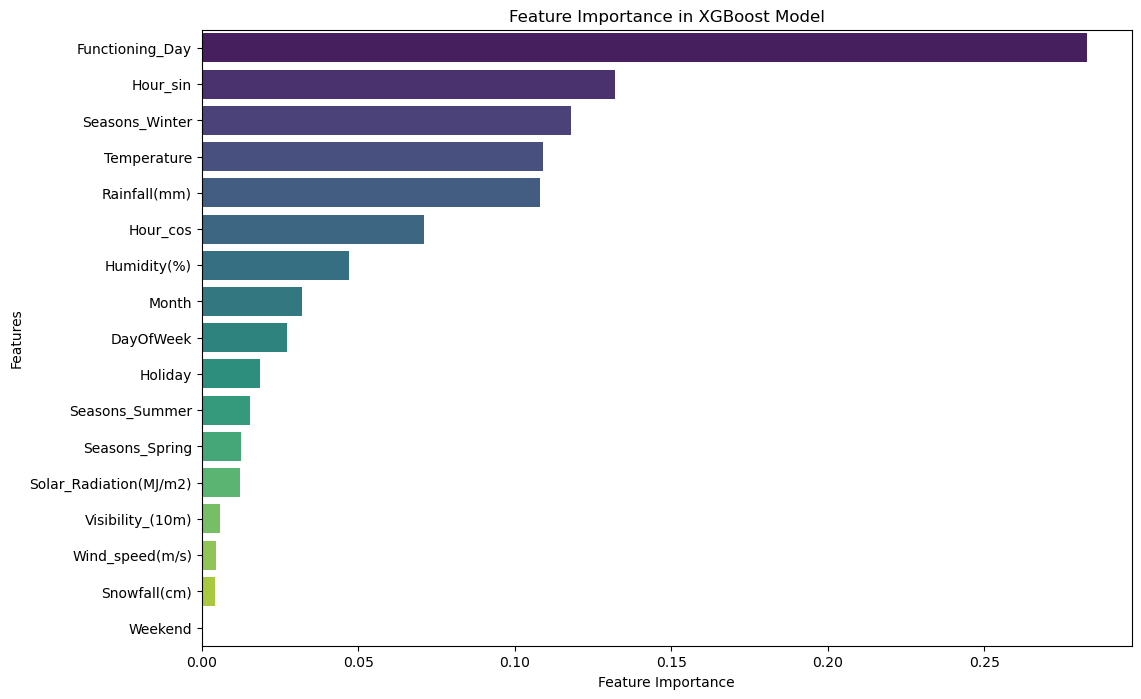

In [406]:
# Feature Importance in XGBoost Model

# Extract feature importance scores
importances = final_xgb.feature_importances_

# Create a sorted Series of feature importances
feature_importances = pd.Series(
    importances,
    index=X_train.columns
).sort_values(ascending=False)

# Plot feature importance
plt.figure(figsize=(12, 8))

sns.barplot(
    x=feature_importances.values,
    y=feature_importances.index,
    hue=feature_importances.index,
    dodge=False,
    palette='viridis',
    legend=False
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Feature Importance in XGBoost Model")

plt.show()

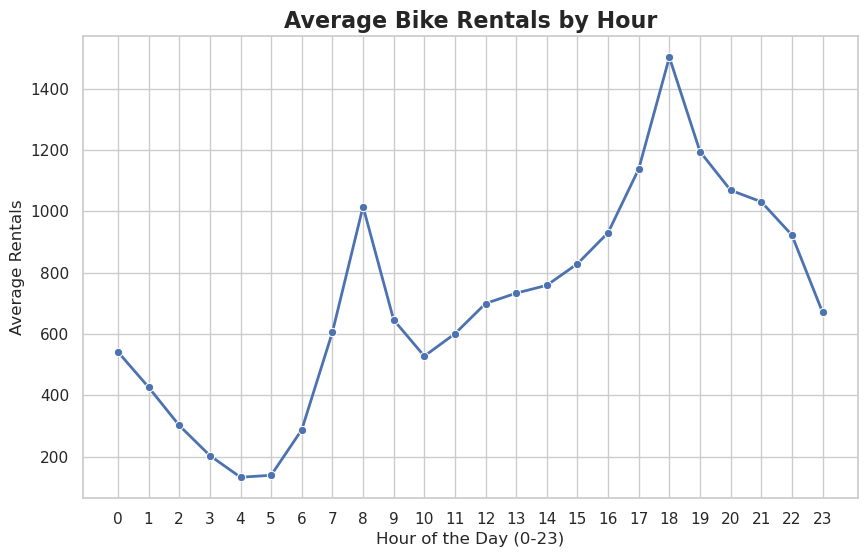

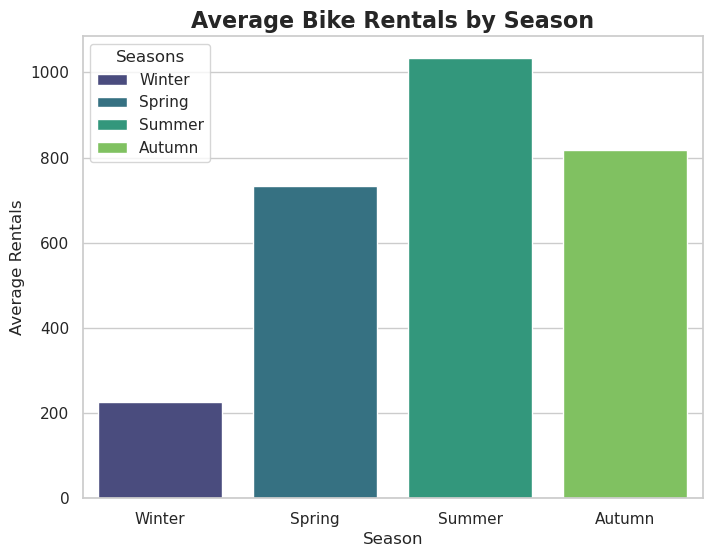

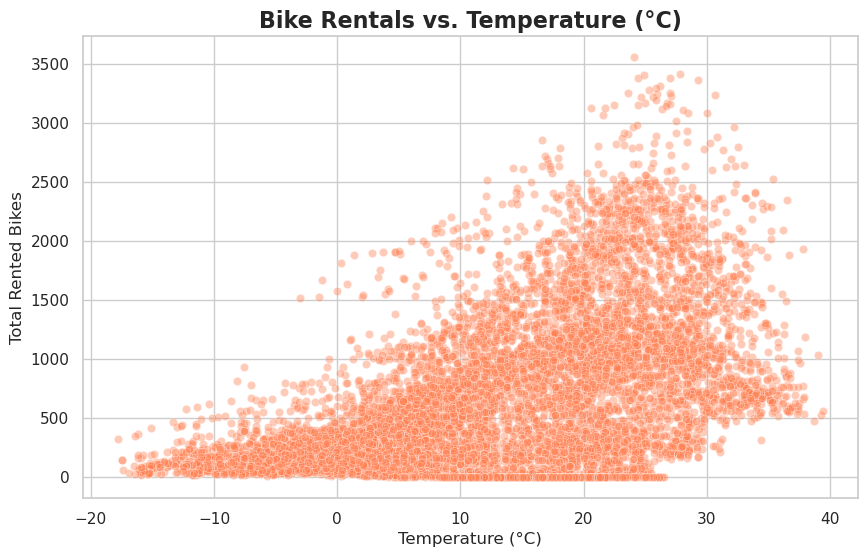

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. BULLETPROOF METHOD: Load a completely fresh, untouched copy of the data
viz_df = pd.read_csv('BikeData.csv')

# 2. Do a lightning-fast clean so the charts work
viz_df.columns = viz_df.columns.str.strip().str.replace(' ', '_')
viz_df["Temperature"] = viz_df["Temperature"].apply(lambda x: float(x.replace('C', '').replace(',', '')) if isinstance(x, str) else x)

# Set a professional visual style
sns.set_theme(style="whitegrid")

# ========================================================
# CHART 1: Average Bike Rentals by Hour (Line Chart)
# ========================================================
plt.figure(figsize=(10, 6))
hourly_trend = viz_df.groupby('Hour')['Rented_Bike_Count'].mean().reset_index()
sns.lineplot(data=hourly_trend, x='Hour', y='Rented_Bike_Count', marker='o', color='b', linewidth=2)

plt.title('Average Bike Rentals by Hour', fontsize=16, fontweight='bold')
plt.xlabel('Hour of the Day (0-23)', fontsize=12)
plt.ylabel('Average Rentals', fontsize=12)
plt.xticks(range(0, 24, 1)) # Shows every single hour on the bottom

plt.show() # This prints the first chart

# ========================================================
# CHART 2: Average Bike Rentals by Season (Bar Chart)
# ========================================================
plt.figure(figsize=(8, 6))
sns.barplot(data=viz_df, x='Seasons', y='Rented_Bike_Count', errorbar=None, palette='viridis', hue='Seasons')

plt.title('Average Bike Rentals by Season', fontsize=16, fontweight='bold')
plt.xlabel('Season', fontsize=12)
plt.ylabel('Average Rentals', fontsize=12)

plt.show() # This prints the second chart

# ========================================================
# CHART 3: The Weather Impact (Scatter Plot)
# ========================================================
plt.figure(figsize=(10, 6))
sns.scatterplot(data=viz_df, x='Temperature', y='Rented_Bike_Count', alpha=0.4, color='coral')

plt.title('Bike Rentals vs. Temperature (°C)', fontsize=16, fontweight='bold')
plt.xlabel('Temperature (°C)', fontsize=12)
plt.ylabel('Total Rented Bikes', fontsize=12)

plt.show() # This prints the third chart